# TuberFed: Federated Tuberculosis Screening on Chest Radiographs

DenseNet121 with and without self-attention, trained with FedAvg and FedProx across non-identical clients, compared with centralised training under a leakage-controlled protocol.

**Data:** Tawsifur Rahman TB database, Shenzhen and Montgomery (NLM) sets. Tawsifur images that are copies of Shenzhen or Montgomery films are detected and removed, and the remaining Tawsifur images are labelled by origin (Belarus TB, RSNA normal). Montgomery is held out as an external test set.

**Run on Kaggle:** GPU accelerator, Internet on, Run All. Missing datasets are downloaded with `kagglehub`. Outputs are written to `OUT_DIR`.

## Configuration

In [5]:
INPUT_ROOT = "/kaggle/input"
OUT_DIR = "/kaggle/working/tb_fl_outputs"
AUTO_ADD_DATASETS = True
REQUIRE_GPU = True

IMG = 224
BLUR_RES = 512
BLUR_THRESHOLD = 0
NEAR_DUP_CORR = 0.985
CROSS_DUP_CORR = 0.97
CROSS_CROP_SCALES = (1.0, 0.92, 0.85)

SPLIT = (0.70, 0.10, 0.20)
DATA_SEED = 42
SEEDS = [0, 1, 2]
CLIENT_C_SIZE = 1000
PARTITIONS = ["paper", "iid", "drop_c"]

NUM_ROUNDS = 15
LOCAL_EPOCHS = 2
BATCH_SIZE = 32
LR = 1e-4
WEIGHTED_FEDAVG = True
FEDPROX_MUS = [0.001, 0.01, 0.1]
RUN_FEDPROX = True
RUN_CENTRALISED = True

PRETRAINED = True
USE_AMP = True
N_BOOT = 2000
LOAD_WORKERS = 8
RESUME = True

## Setup

In [6]:
import os, re, io, sys, json, time, copy, glob, hashlib, random, warnings, platform, pickle, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn import metrics as skm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from scipy import stats
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

FIG_DIR = os.path.join(OUT_DIR, "figures")
for d in (OUT_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and device.type == "cuda"

ENV = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "opencv": cv2.__version__,
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "none (CPU)",
}
print(json.dumps(ENV, indent=2))
json.dump(ENV, open(os.path.join(OUT_DIR, "environment.json"), "w"), indent=2)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches="tight")

def save_table(df_, name):
    df_.to_csv(os.path.join(OUT_DIR, name), index=False)

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "scikit-learn": "1.6.1",
  "opencv": "4.14.0",
  "gpu": "Tesla T4"
}


In [7]:
def find_dir(roots, predicate):
    for root in roots:
        for d, subdirs, files in os.walk(root):
            if predicate(d, subdirs, files):
                return d
    return None

def not_mask(d): return "mask" not in d.lower()
IS_TAWSIF = lambda d, s, f: os.path.basename(d) == "TB_Chest_Radiography_Database"
IS_SHENZHEN = lambda d, s, f: not_mask(d) and sum(x.upper().startswith("CHNCXR") for x in f) > 100
IS_MONT = lambda d, s, f: not_mask(d) and sum(x.upper().startswith("MCUCXR") for x in f) > 50
NEEDED = [("Tawsifur Rahman TB", "tawsifurrahman/tuberculosis-tb-chest-xray-dataset", IS_TAWSIF),
          ("Shenzhen", "raddar/tuberculosis-chest-xrays-shenzhen", IS_SHENZHEN),
          ("Montgomery", "raddar/tuberculosis-chest-xrays-montgomery", IS_MONT)]

SEARCH_ROOTS, problems = [INPUT_ROOT], []
for name, handle, pred in NEEDED:
    if find_dir(SEARCH_ROOTS, pred):
        print(f"[ok]  {name}"); continue
    if not AUTO_ADD_DATASETS:
        problems.append(f"{name} missing: Add Input -> {handle}"); continue
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        path = kagglehub.dataset_download(handle)
        SEARCH_ROOTS.append(path)
        if find_dir([path], pred): print(f"[add] {name} -> {path}")
        else: problems.append(f"{name}: downloaded to {path} but the expected files were not found")
    except Exception as e:
        problems.append(f"{name}: download failed ({type(e).__name__}: {e}); add it manually: {handle}")

if REQUIRE_GPU and device.type != "cuda":
    problems.append("No GPU: Settings -> Accelerator -> GPU, then Run All.")
if problems:
    raise RuntimeError("\n - ".join(["Fix and Run All again:"] + problems))

[ok]  Tawsifur Rahman TB
[ok]  Shenzhen
[ok]  Montgomery


## Data

In [8]:
IMG_EXT = (".png", ".jpg", ".jpeg")
TAWSIF_DIR = find_dir(SEARCH_ROOTS, IS_TAWSIF)
SHENZHEN_DIR = find_dir(SEARCH_ROOTS, IS_SHENZHEN)
MONT_DIR = find_dir(SEARCH_ROOTS, IS_MONT)

records = []
for sub, lab in (("Tuberculosis", 1), ("Normal", 0)):
    folder = os.path.join(TAWSIF_DIR, sub)
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith(IMG_EXT):
            records.append(dict(path=os.path.join(folder, f), source="Tawsifur", label=lab))

def read_metadata_labels(img_dir):
    labels = {}
    for csv in glob.glob(os.path.join(os.path.dirname(os.path.dirname(img_dir)), "*.csv")):
        m = pd.read_csv(csv)
        if {"study_id", "findings"} <= set(m.columns):
            labels.update({str(r.study_id): int(str(r.findings).strip().lower() != "normal") for r in m.itertuples()})
    return labels

def nlm_records(img_dir, source):
    meta, rows, disagree = read_metadata_labels(img_dir), [], 0
    for f in sorted(os.listdir(img_dir)):
        if not f.lower().endswith(IMG_EXT): continue
        mt = re.search(r"_(\d)\.(png|jpg|jpeg)$", f, re.I)
        lab = int(mt.group(1)) if mt else meta.get(f)
        if lab is None: continue
        disagree += int(f in meta and meta[f] != lab)
        rows.append(dict(path=os.path.join(img_dir, f), source=source, label=lab))
    print(f"{source}: {len(rows)} images, file-name vs metadata label disagreements = {disagree}")
    return rows

records += nlm_records(SHENZHEN_DIR, "Shenzhen") + nlm_records(MONT_DIR, "Montgomery")
raw_df = pd.DataFrame(records)
print(raw_df.groupby(["source", "label"]).size().rename("images").to_string())

Shenzhen: 662 images, file-name vs metadata label disagreements = 0
Montgomery: 138 images, file-name vs metadata label disagreements = 0
source      label
Montgomery  0          80
            1          58
Shenzhen    0         326
            1         336
Tawsifur    0        3500
            1         700


In [9]:
def process(path):
    try:
        raw = open(path, "rb").read()
        Image.open(io.BytesIO(raw)).verify()
        arr = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE)
        if arr is None: return dict(status="corrupt")
        b = arr if BLUR_RES is None else cv2.resize(arr, (BLUR_RES, BLUR_RES), interpolation=cv2.INTER_AREA)
        return dict(status="ok", md5=hashlib.md5(raw).hexdigest(), blur=float(cv2.Laplacian(b, cv2.CV_64F).var()),
                    img=cv2.resize(arr, (IMG, IMG), interpolation=cv2.INTER_AREA))
    except Exception:
        return dict(status="corrupt")

t0 = time.time()
with ThreadPoolExecutor(LOAD_WORKERS) as ex:
    out = list(ex.map(process, raw_df.path.tolist()))
print(f"decoded {len(out)} images in {time.time() - t0:.0f}s")

raw_df["status"] = [o["status"] for o in out]
raw_df["blur"] = [o.get("blur", np.nan) for o in out]
raw_df["md5"] = [o.get("md5") for o in out]
if BLUR_THRESHOLD:
    raw_df.loc[(raw_df.status == "ok") & (raw_df.blur < BLUR_THRESHOLD), "status"] = "blurry"

ok = raw_df.status == "ok"
conflict = raw_df[ok].groupby("md5").label.nunique()
raw_df.loc[ok & raw_df.md5.isin(set(conflict[conflict > 1].index)), "status"] = "label_conflict"
ok = raw_df.status == "ok"
raw_df.loc[ok & raw_df.duplicated("md5", keep="first"), "status"] = "duplicate"

CLEANING = raw_df.groupby(["source", "label", "status"]).size().unstack(fill_value=0)
print(CLEANING.to_string())
CLEANING.to_csv(os.path.join(OUT_DIR, "cleaning_summary.csv"))

keep = (raw_df.status == "ok").to_numpy()
df = raw_df[keep].reset_index(drop=True)
IMGS = np.stack([out[i]["img"] for i in np.where(keep)[0]])
del out
print(f"kept {len(df)} images")

decoded 5000 images in 97s
status            duplicate    ok
source     label                 
Montgomery 0              0    80
           1              0    58
Shenzhen   0              0   326
           1              0   336
Tawsifur   0              0  3500
           1              3   697
kept 4997 images


## Cross-collection audit

{
  "threshold": 0.97,
  "crop_scales": [
    1.0,
    0.92,
    0.85
  ],
  "n_tawsifur": 4197,
  "n_copies": 0,
  "copies_tb": 0,
  "copies_normal": 0,
  "copies_by_source": {},
  "label_agreement": NaN,
  "score_quantiles": {
    "0.5": 0.8691398501396179,
    "0.9": 0.9109333038330079,
    "0.99": 0.9317619585990906
  },
  "expected_nlm_in_tawsifur": {
    "tb": 394,
    "normal": 406
  }
}


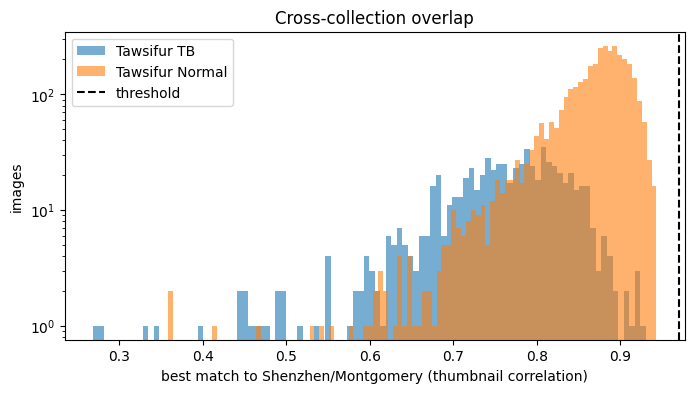

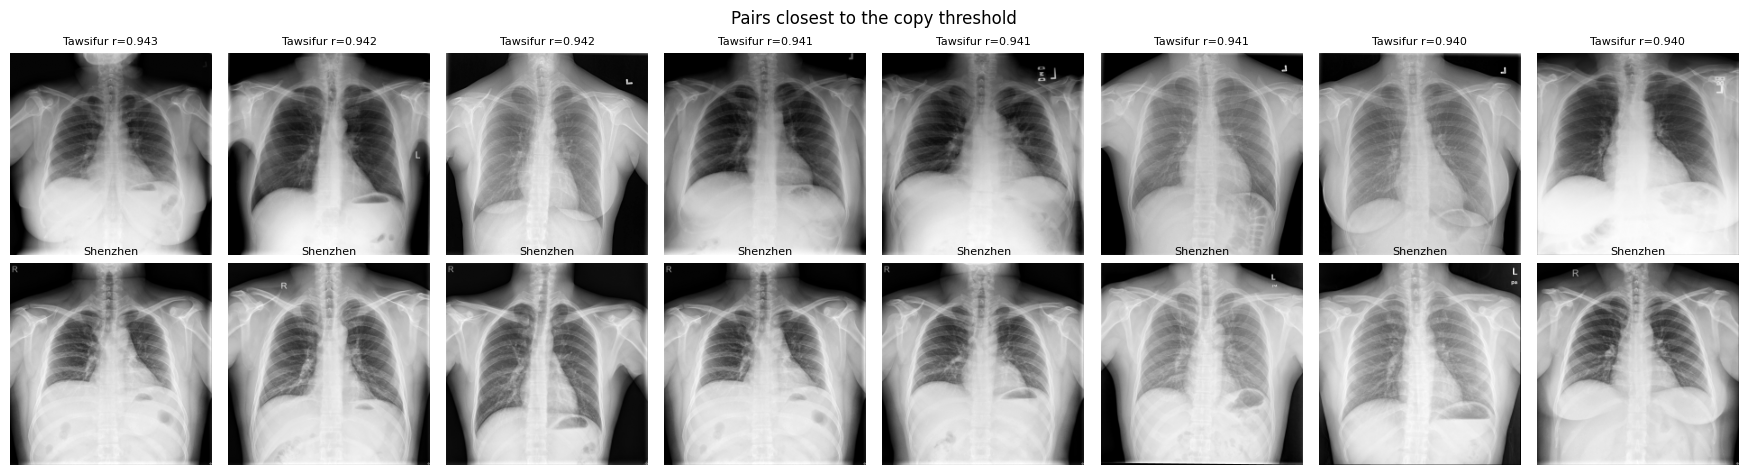

    source     origin  label  images
Montgomery Montgomery      0      80
Montgomery Montgomery      1      58
  Shenzhen   Shenzhen      0     326
  Shenzhen   Shenzhen      1     336
  Tawsifur    Belarus      1     697
  Tawsifur       RSNA      0    3500


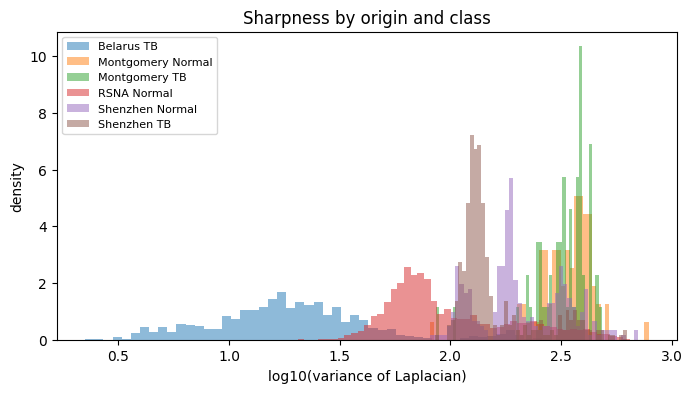

In [10]:
def make_thumbs(idx, scale=1.0, rank=False):
    T = np.empty((len(idx), 4096), np.float32)
    c = int(round(IMG * (1 - scale) / 2))
    for k, i in enumerate(idx):
        im = IMGS[i][c:IMG - c, c:IMG - c] if c else IMGS[i]
        v = cv2.resize(im, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
        if rank: v = stats.rankdata(v).astype(np.float32)
        v -= v.mean(); T[k] = v / (np.linalg.norm(v) + 1e-8)
    return T

def best_match(query, reference, scales=(1.0,), chunk=1024):
    best, match = np.full(len(query), -1.0), np.zeros(len(query), int)
    for rank in (False, True):
        Q = make_thumbs(query, 1.0, rank)
        for s in scales:
            R = make_thumbs(reference, s, rank)
            for k in range(0, len(query), chunk):
                C = Q[k:k + chunk] @ R.T
                b, a = C.max(1), C.argmax(1)
                upd = b > best[k:k + chunk]
                best[k:k + chunk][upd] = b[upd]
                match[k:k + chunk][upd] = reference[a[upd]]
    return best, match

tw = df.index[df.source == "Tawsifur"].to_numpy()
ref = df.index[df.source.isin(["Shenzhen", "Montgomery"])].to_numpy()
cross_best, cross_match = best_match(tw, ref, CROSS_CROP_SCALES)
is_copy = cross_best >= CROSS_DUP_CORR
tw_lab = df.loc[tw, "label"].to_numpy()

COPIES = pd.DataFrame(dict(
    tawsifur_path=df.loc[tw[is_copy], "path"].values, tawsifur_label=tw_lab[is_copy],
    match_path=df.loc[cross_match[is_copy], "path"].values, match_source=df.loc[cross_match[is_copy], "source"].values,
    match_label=df.loc[cross_match[is_copy], "label"].values, score=cross_best[is_copy])).sort_values("score")
save_table(COPIES, "cross_collection_copies.csv")

AUDIT = dict(
    threshold=CROSS_DUP_CORR, crop_scales=list(CROSS_CROP_SCALES), n_tawsifur=int(len(tw)), n_copies=int(is_copy.sum()),
    copies_tb=int((is_copy & (tw_lab == 1)).sum()), copies_normal=int((is_copy & (tw_lab == 0)).sum()),
    copies_by_source=COPIES.match_source.value_counts().to_dict(),
    label_agreement=float((COPIES.tawsifur_label == COPIES.match_label).mean()) if len(COPIES) else float("nan"),
    score_quantiles={str(q): float(np.quantile(cross_best, q)) for q in (0.5, 0.9, 0.99)},
    expected_nlm_in_tawsifur=dict(tb=394, normal=406))
print(json.dumps(AUDIT, indent=2))

fig, ax = plt.subplots(figsize=(8, 4))
for lab, name in ((1, "Tawsifur TB"), (0, "Tawsifur Normal")):
    ax.hist(cross_best[tw_lab == lab], bins=100, alpha=.6, label=name)
ax.axvline(CROSS_DUP_CORR, color="k", ls="--", label="threshold")
ax.set(xlabel="best match to Shenzhen/Montgomery (thumbnail correlation)", ylabel="images", yscale="log",
       title="Cross-collection overlap")
ax.legend(); savefig("cross_collection_hist.png"); plt.show()

order = np.argsort(np.abs(cross_best - CROSS_DUP_CORR))[:8]
fig, ax = plt.subplots(2, len(order), figsize=(2.2 * len(order), 4.8))
for c, t in enumerate(order):
    ax[0, c].imshow(IMGS[tw[t]], cmap="gray"); ax[0, c].set_title(f"Tawsifur r={cross_best[t]:.3f}", fontsize=8)
    ax[1, c].imshow(IMGS[cross_match[t]], cmap="gray"); ax[1, c].set_title(df.source[cross_match[t]], fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Pairs closest to the copy threshold"); plt.tight_layout(); savefig("cross_collection_pairs.png"); plt.show()

df["origin"] = df["source"]
df.loc[tw[~is_copy & (tw_lab == 1)], "origin"] = "Belarus"
df.loc[tw[~is_copy & (tw_lab == 0)], "origin"] = "RSNA"
keep = np.ones(len(df), bool); keep[tw[is_copy]] = False
df, IMGS = df[keep].reset_index(drop=True), IMGS[keep]

ORIGINS = df.groupby(["source", "origin", "label"]).size().rename("images").reset_index()
print(ORIGINS.to_string(index=False))
save_table(ORIGINS, "origins.csv")
for org, exp_n in (("Belarus", 306), ("RSNA", 3094)):
    n = int((df.origin == org).sum())
    if abs(n - exp_n) > 0.1 * exp_n:
        print(f"warning: {n} images labelled {org}, {exp_n} expected; check the overlap histogram and pairs")

plt.figure(figsize=(8, 4))
for (org, lab), g in df.groupby(["origin", "label"]):
    plt.hist(np.log10(g.blur + 1e-6), bins=50, alpha=.5, density=True, label=f"{org} {'TB' if lab else 'Normal'}")
plt.xlabel("log10(variance of Laplacian)"); plt.ylabel("density"); plt.title("Sharpness by origin and class")
plt.legend(fontsize=8); savefig("blur_by_origin.png"); plt.show()

## Splits and federated clients

In [11]:
rng = np.random.default_rng(DATA_SEED)
df["split"] = ""
df.loc[df.source == "Montgomery", "split"] = "external"
for src, g in df[df.source != "Montgomery"].groupby("source"):
    tr, tmp = train_test_split(g.index, test_size=SPLIT[1] + SPLIT[2], stratify=g.label, random_state=DATA_SEED)
    va, te = train_test_split(tmp, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]), stratify=df.loc[tmp, "label"],
                              random_state=DATA_SEED)
    df.loc[tr, "split"], df.loc[va, "split"], df.loc[te, "split"] = "train", "val", "test"

tr_all = df.index[df.split == "train"].to_numpy()
ev_all = df.index[df.split.isin(["val", "test", "external"])].to_numpy()
near_best, near_match = best_match(ev_all, tr_all)
near = near_best >= NEAR_DUP_CORR
df.loc[ev_all[near], "split"] = "unused"
NEAR_DUP = dict(threshold=NEAR_DUP_CORR, removed=int(near.sum()),
                removed_by_source=df.loc[ev_all[near], "source"].value_counts().to_dict(),
                best_corr_quantiles={str(q): float(np.quantile(near_best, q)) for q in (0.5, 0.9, 0.99, 1.0)})
print(json.dumps(NEAR_DUP, indent=2))

for sp in ("val", "test"):
    tb = df[(df.source == "Tawsifur") & (df.split == sp) & (df.label == 1)]
    nm = df[(df.source == "Tawsifur") & (df.split == sp) & (df.label == 0)]
    df.loc[rng.choice(nm.index, size=max(len(nm) - len(tb), 0), replace=False), "split"] = "unused"

tr = df[df.split == "train"]
tw_tb = tr[(tr.source == "Tawsifur") & (tr.label == 1)].index.to_numpy()
tw_nm = rng.permutation(tr[(tr.source == "Tawsifur") & (tr.label == 0)].index.to_numpy())
paper_clients = {
    "Client A (Tawsifur)": np.concatenate([tw_tb, tw_nm[:len(tw_tb)]]),
    "Client B (Shenzhen)": tr[tr.source == "Shenzhen"].index.to_numpy(),
    "Client C (Tawsifur normal)": tw_nm[len(tw_tb):len(tw_tb) + CLIENT_C_SIZE],
}
used_train = np.concatenate(list(paper_clients.values()))
df.loc[df.index.isin(tr.index.difference(used_train)), "split"] = "unused"

perm = rng.permutation(used_train)
ALL_PARTITIONS = {
    "paper": paper_clients,
    "iid": {f"Client {c} (IID)": np.sort(a) for c, a in zip("ABC", np.array_split(perm, 3))},
    "drop_c": {k: v for k, v in paper_clients.items() if not k.startswith("Client C")},
}
PARTITION_IDX = {p: ALL_PARTITIONS[p] for p in ["paper"] + [p for p in PARTITIONS if p != "paper"]}

val_idx = df.index[df.split == "val"].to_numpy()
test_idx = df.index[df.split == "test"].to_numpy()
ext_idx = df.index[df.split == "external"].to_numpy()

flat = np.concatenate(list(paper_clients.values()) + [val_idx, test_idx, ext_idx])
assert len(flat) == len(set(flat))
assert sorted(np.concatenate(list(PARTITION_IDX.get("iid", paper_clients).values()))) == sorted(used_train)
for idx in (val_idx, test_idx, ext_idx):
    assert not set(df.loc[idx, "md5"]) & set(df.loc[used_train, "md5"])
    assert not set(df.loc[idx, "path"]) & set(df.loc[used_train, "path"])
print("leakage checks passed")

def describe(name, idx, part):
    s = df.loc[idx]
    return dict(partition=part, set=name, origins=", ".join(sorted(s.origin.unique())),
                TB=int((s.label == 1).sum()), Normal=int((s.label == 0).sum()), Total=len(s))
rows = []
for part, clients in PARTITION_IDX.items():
    n_all = sum(len(v) for v in clients.values())
    for name, idx in clients.items():
        rows.append(describe(name, idx, part) | dict(fedavg_weight=round(len(idx) / n_all, 3)))
for name, idx in (("Validation", val_idx), ("Test", test_idx), ("External (Montgomery)", ext_idx)):
    rows.append(describe(name, idx, "all"))
TABLE_DATA = pd.DataFrame(rows)
print(TABLE_DATA.to_string(index=False))
save_table(TABLE_DATA, "table_data_distribution.csv")

SPLIT_ID = hashlib.md5("|".join(sorted(df.loc[flat, "path"])).encode()).hexdigest()[:8]
RUN_DIR = os.path.join(OUT_DIR, "runs", SPLIT_ID)
os.makedirs(RUN_DIR, exist_ok=True)
print("split id:", SPLIT_ID)

{
  "threshold": 0.985,
  "removed": 3,
  "removed_by_source": {
    "Tawsifur": 3
  },
  "best_corr_quantiles": {
    "0.5": 0.9012795090675354,
    "0.9": 0.9376328587532043,
    "0.99": 0.9584493374824524,
    "1.0": 0.9999997615814209
  }
}
leakage checks passed
partition                        set                 origins  TB  Normal  Total  fedavg_weight
    paper        Client A (Tawsifur)           Belarus, RSNA 488     488    976          0.400
    paper        Client B (Shenzhen)                Shenzhen 235     228    463          0.190
    paper Client C (Tawsifur normal)                    RSNA   0    1000   1000          0.410
      iid             Client A (IID) Belarus, RSNA, Shenzhen 252     561    813          0.333
      iid             Client B (IID) Belarus, RSNA, Shenzhen 225     588    813          0.333
      iid             Client C (IID) Belarus, RSNA, Shenzhen 246     567    813          0.333
   drop_c        Client A (Tawsifur)           Belarus, RSNA 488    

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

class Split:
    def __init__(self, idx):
        self.idx = np.asarray(idx)
        self.X = torch.from_numpy(IMGS[self.idx])
        self.y = torch.tensor(df.loc[self.idx, "label"].values, dtype=torch.long)
        self.source = df.loc[self.idx, "source"].values
        self.origin = df.loc[self.idx, "origin"].values
        self.path = df.loc[self.idx, "path"].values
    def __len__(self): return len(self.y)

def to_input(xb):
    x = xb.to(device, non_blocking=True).float().div_(255).unsqueeze(1).expand(-1, 3, -1, -1)
    return (x - MEAN) / STD

def batches(split, bs, shuffle, gen=None):
    order = torch.randperm(len(split), generator=gen) if shuffle else torch.arange(len(split))
    for i in range(0, len(split), bs):
        j = order[i:i + bs]
        yield to_input(split.X[j]), split.y[j].to(device)

CLIENT_SETS = {p: {n: Split(i) for n, i in c.items()} for p, c in PARTITION_IDX.items()}
POOLED_SETS = {p: Split(np.concatenate(list(c.values()))) for p, c in PARTITION_IDX.items()}
VAL, TEST, EXT = Split(val_idx), Split(test_idx), Split(ext_idx)
y_val, y_test, y_ext = VAL.y.numpy(), TEST.y.numpy(), EXT.y.numpy()
print({p: {n: len(s) for n, s in c.items()} for p, c in CLIENT_SETS.items()})
print("val", len(VAL), "| test", len(TEST), "| external", len(EXT))

{'paper': {'Client A (Tawsifur)': 976, 'Client B (Shenzhen)': 463, 'Client C (Tawsifur normal)': 1000}, 'iid': {'Client A (IID)': 813, 'Client B (IID)': 813, 'Client C (IID)': 813}, 'drop_c': {'Client A (Tawsifur)': 976, 'Client B (Shenzhen)': 463}}
val 204 | test 407 | external 138


## Models

In [13]:
N_TOKENS = (IMG // 32) ** 2

def densenet_features():
    w = models.DenseNet121_Weights.IMAGENET1K_V1 if PRETRAINED else None
    return models.densenet121(weights=w).features

class DenseNetAttention(nn.Module):
    def __init__(self, num_classes=2, heads=8, p_drop=0.4):
        super().__init__()
        self.backbone = densenet_features()
        self.attention = nn.MultiheadAttention(embed_dim=1024, num_heads=heads)
        self.fc = nn.Sequential(nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(256, num_classes))
    def forward_features(self, x): return self.backbone(x)
    def embed(self, feats):
        t = feats.flatten(2).permute(2, 0, 1)
        return self.attention(t, t, t, need_weights=False)[0].mean(0)
    def forward_head(self, feats): return self.fc(self.embed(feats))
    def forward(self, x): return self.forward_head(self.forward_features(x))

class DenseNetBaseline(DenseNetAttention):
    def __init__(self, num_classes=2, p_drop=0.4):
        super().__init__(num_classes=num_classes, p_drop=p_drop)
        del self.attention
    def embed(self, feats): return feats.flatten(2).mean(2)

class ResidualAttentionBlock(nn.Module):
    def __init__(self, dim=1024, heads=8, n_tokens=49, p=0.1):
        super().__init__()
        self.pos = nn.Parameter(torch.zeros(n_tokens, 1, dim)); nn.init.trunc_normal_(self.pos, std=0.02)
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=p)
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.GELU(), nn.Dropout(p), nn.Linear(dim, dim))
        for layer in (self.attn.out_proj, self.mlp[-1]):
            nn.init.zeros_(layer.weight); nn.init.zeros_(layer.bias)
    def forward(self, t):
        t = t + self.pos
        h = self.norm1(t)
        t = t + self.attn(h, h, h, need_weights=False)[0]
        return t + self.mlp(self.norm2(t))

class DenseNetResAttention(DenseNetAttention):
    def __init__(self, num_classes=2, heads=8, p_drop=0.4):
        super().__init__(num_classes=num_classes, heads=heads, p_drop=p_drop)
        self.attention = ResidualAttentionBlock(1024, heads, N_TOKENS)
    def embed(self, feats): return self.attention(feats.flatten(2).permute(2, 0, 1)).mean(0)

ARCH = {"Base": DenseNetBaseline, "Attn": DenseNetAttention, "ResAttn": DenseNetResAttention}
def n_params(m): return sum(p.numel() for p in m.parameters())
N_PARAMS = {a: n_params(c()) for a, c in ARCH.items()}
print({a: f"{n / 1e6:.2f} M" for a, n in N_PARAMS.items()})

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 166MB/s]


{'Base': '7.22 M', 'Attn': '11.42 M', 'ResAttn': '13.57 M'}


## Training and evaluation functions

In [14]:
def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=AMP_ON)
    except Exception: return torch.cuda.amp.GradScaler(enabled=AMP_ON)

def train_epochs(model, split, epochs, opt, scaler, gen, prox_ref=None, mu=0.0):
    model.train(); tot_loss = tot_ok = tot = 0
    for _ in range(epochs):
        for xb, yb in batches(split, BATCH_SIZE, True, gen):
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
                out = model(xb); ce = F.cross_entropy(out, yb)
            loss = ce.float()
            if mu > 0:
                loss = loss + 0.5 * mu * sum((p - r).pow(2).sum() for p, r in zip(model.parameters(), prox_ref))
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot_loss += ce.item() * len(yb); tot_ok += (out.argmax(1) == yb).sum().item(); tot += len(yb)
    return tot_loss / tot, tot_ok / tot

def local_train(global_model, split, seed, mu=0.0):
    model = copy.deepcopy(global_model)
    prox_ref = [p.detach().clone() for p in global_model.parameters()] if mu > 0 else None
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss, acc = train_epochs(model, split, LOCAL_EPOCHS, opt, make_scaler(), torch.Generator().manual_seed(seed),
                             prox_ref, mu)
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    del model, opt
    return state, len(split), loss, acc

def fedavg(states, sizes):
    w = np.asarray(sizes, float)
    w = w / w.sum() if WEIGHTED_FEDAVG else np.full(len(states), 1 / len(states))
    return {k: (sum(float(wi) * s[k] for wi, s in zip(w, states)) if states[0][k].is_floating_point()
                else states[0][k].clone()) for k in states[0]}

@torch.no_grad()
def predict(model, split, bs=64):
    model.eval(); probs, loss = [], 0.0
    for xb, yb in batches(split, bs, False):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
            out = model(xb)
        out = out.float()
        loss += F.cross_entropy(out, yb, reduction="sum").item()
        probs.append(torch.softmax(out, 1)[:, 1].cpu())
    return torch.cat(probs).numpy(), loss / len(split)

def ece_score(y, p, n_bins=10):
    ids = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return float(sum((ids == b).mean() * abs(y[ids == b].mean() - p[ids == b].mean())
                     for b in range(n_bins) if (ids == b).any()))

def compute_metrics(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p); yh = (p >= thr).astype(int)
    tn, fp, fn, tp = skm.confusion_matrix(y, yh, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return dict(n=len(y), tp=int(tp), fn=int(fn), tn=int(tn), fp=int(fp), threshold=float(thr),
                accuracy=(tp + tn) / len(y),
                sensitivity=tp / (tp + fn) if tp + fn else np.nan,
                specificity=tn / (tn + fp) if tn + fp else np.nan,
                precision=tp / (tp + fp) if tp + fp else np.nan,
                f1=skm.f1_score(y, yh, zero_division=0),
                auc=skm.roc_auc_score(y, p) if both else np.nan,
                ap=skm.average_precision_score(y, p) if both else np.nan,
                kappa=skm.cohen_kappa_score(y, yh) if both else np.nan,
                mcc=skm.matthews_corrcoef(y, yh) if both else np.nan,
                brier=skm.brier_score_loss(y, p, pos_label=1), ece=ece_score(y, p))

def youden_threshold(y, p):
    fpr, tpr, thr = skm.roc_curve(y, p)
    return float(min(thr[np.argmax(tpr - fpr)], 1.0))

def _light(y, p, thr=0.5):
    yh = p >= thr; tp = (yh & (y == 1)).sum(); tn = (~yh & (y == 0)).sum()
    P, N = (y == 1).sum(), (y == 0).sum()
    return dict(accuracy=(tp + tn) / len(y), sensitivity=tp / P, specificity=tn / N,
                f1=2 * tp / (2 * tp + (N - tn) + (P - tp)), auc=skm.roc_auc_score(y, p))

def bootstrap_ci(y, p, thr=0.5, n=N_BOOT, seed=0):
    rng_ = np.random.default_rng(seed); vals = {}
    for _ in range(n):
        i = rng_.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        for k, v in _light(y[i], p[i], thr).items(): vals.setdefault(k, []).append(v)
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in vals.items()}

def paired_bootstrap_diff(y, p_a, p_b, n=N_BOOT, seed=0):
    rng_ = np.random.default_rng(seed); d = {"accuracy": [], "auc": []}
    for _ in range(n):
        i = rng_.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        a, b = _light(y[i], p_a[i]), _light(y[i], p_b[i])
        for k in d: d[k].append(a[k] - b[k])
    return {k: (float(np.mean(v)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in d.items()}

def mcnemar_exact(y, p_a, p_b):
    ca, cb = (p_a >= .5) == y, (p_b >= .5) == y
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return b, c, (stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0)

In [15]:
def snapshot(model): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def run_federated(model_cls, seed, clients, mu=0.0):
    set_seed(seed)
    gmodel = model_cls().to(device)
    hist, best = [], dict(val_loss=np.inf)
    for r in range(1, NUM_ROUNDS + 1):
        t0 = time.time(); states, sizes, rec = [], [], dict(round=r)
        for ci, (name, split) in enumerate(clients.items()):
            s, n, l, a = local_train(gmodel, split, seed * 10_000 + r * 10 + ci, mu)
            states.append(s); sizes.append(n); rec[f"{name} loss"], rec[f"{name} acc"] = l, a
        gmodel.load_state_dict(fedavg(states, sizes)); del states
        w = np.asarray(sizes) / sum(sizes)
        rec["train_loss"] = float(sum(wi * rec[f"{n} loss"] for wi, n in zip(w, clients)))
        rec["train_acc"] = float(sum(wi * rec[f"{n} acc"] for wi, n in zip(w, clients)))
        pv, vloss = predict(gmodel, VAL); vm = compute_metrics(y_val, pv)
        rec.update(val_loss=vloss, val_acc=vm["accuracy"], val_auc=vm["auc"], seconds=time.time() - t0)
        hist.append(rec)
        print(f"  round {r:2d} | train {rec['train_loss']:.4f}/{rec['train_acc']:.4f} | "
              f"val {vloss:.4f}/{vm['accuracy']:.4f} auc {vm['auc']:.4f} | {rec['seconds']:.0f}s")
        if vloss < best["val_loss"]: best = dict(val_loss=vloss, round=r, state=snapshot(gmodel))
    gmodel.load_state_dict(best["state"])
    return gmodel, pd.DataFrame(hist), best["round"], best["val_loss"]

def run_centralised(model_cls, seed, pooled):
    set_seed(seed)
    model = model_cls().to(device)
    opt, scaler, gen = torch.optim.Adam(model.parameters(), lr=LR), make_scaler(), torch.Generator().manual_seed(seed)
    hist, best = [], dict(val_loss=np.inf)
    for ep in range(1, NUM_ROUNDS * LOCAL_EPOCHS + 1):
        t0 = time.time()
        l, a = train_epochs(model, pooled, 1, opt, scaler, gen)
        pv, vloss = predict(model, VAL); vm = compute_metrics(y_val, pv)
        hist.append(dict(round=ep, train_loss=l, train_acc=a, val_loss=vloss, val_acc=vm["accuracy"],
                         val_auc=vm["auc"], seconds=time.time() - t0))
        print(f"  epoch {ep:2d} | train {l:.4f}/{a:.4f} | val {vloss:.4f}/{vm['accuracy']:.4f}")
        if vloss < best["val_loss"]: best = dict(val_loss=vloss, round=ep, state=snapshot(model))
    model.load_state_dict(best["state"])
    return model, pd.DataFrame(hist), best["round"], best["val_loss"]

## Experiments

In [16]:
CACHE = {}

def run_path(part, tag, seed, ext):
    d = os.path.join(RUN_DIR, part); os.makedirs(d, exist_ok=True)
    return os.path.join(d, f"{tag}_seed{seed}.{ext}")

def execute(part, tag, arch, seed, method, mu=0.0):
    f_pkl, f_pt = run_path(part, tag, seed, "pkl"), run_path(part, tag, seed, "pt")
    if f_pkl in CACHE: return CACHE[f_pkl]
    if RESUME and os.path.exists(f_pkl) and os.path.exists(f_pt):
        CACHE[f_pkl] = pickle.load(open(f_pkl, "rb")); print(f"[loaded] {part} | {tag} | seed {seed}")
        return CACHE[f_pkl]
    print(f"\n=== {part} | {tag} | seed {seed} ===")
    t0 = time.time()
    if method == "central":
        model, hist, br, bvl = run_centralised(ARCH[arch], seed, POOLED_SETS[part])
    else:
        model, hist, br, bvl = run_federated(ARCH[arch], seed, CLIENT_SETS[part], mu)
    p_val, _ = predict(model, VAL); p_test, _ = predict(model, TEST); p_ext, _ = predict(model, EXT)
    thr = youden_threshold(y_val, p_val)
    res = dict(partition=part, tag=tag, arch=arch, method=method, mu=mu, seed=seed, hist=hist, best_round=br,
               best_val_loss=bvl, thr_val=thr, p_val=p_val, p_test=p_test, p_ext=p_ext,
               metrics=compute_metrics(y_test, p_test), metrics_val_thr=compute_metrics(y_test, p_test, thr),
               minutes=(time.time() - t0) / 60, weights=f_pt)
    torch.save(model.state_dict(), f_pt); pickle.dump(res, open(f_pkl, "wb"))
    hist.to_csv(run_path(part, tag, seed, "csv"), index=False)
    print(f"best round {br} | test acc {res['metrics']['accuracy']:.4f} auc {res['metrics']['auc']:.4f} | "
          f"val threshold {thr:.3f} | {res['minutes']:.1f} min")
    del model; torch.cuda.empty_cache()
    CACHE[f_pkl] = res
    return res

RESULTS = {}
for seed in SEEDS:
    for arch in ARCH:
        RESULTS[("paper", f"FedAvg-{arch}", seed)] = execute("paper", f"FedAvg-{arch}", arch, seed, "fedavg")
        if RUN_CENTRALISED:
            RESULTS[("paper", f"Central-{arch}", seed)] = execute("paper", f"Central-{arch}", arch, seed, "central")

MU_SEARCH, MU_CHOICE = [], {}
if RUN_FEDPROX:
    for arch in ARCH:
        cand = {mu: execute("paper", f"FedProx-{arch}-mu{mu:g}", arch, SEEDS[0], "fedprox", mu) for mu in FEDPROX_MUS}
        MU_CHOICE[arch] = min(cand, key=lambda m: cand[m]["best_val_loss"])
        MU_SEARCH += [dict(arch=arch, mu=mu, best_val_loss=r["best_val_loss"], best_round=r["best_round"],
                           selected=mu == MU_CHOICE[arch]) for mu, r in cand.items()]
        for seed in SEEDS:
            mu = MU_CHOICE[arch]
            RESULTS[("paper", f"FedProx-{arch}", seed)] = execute("paper", f"FedProx-{arch}-mu{mu:g}", arch, seed,
                                                                  "fedprox", mu)
    TABLE_MU = pd.DataFrame(MU_SEARCH); print(TABLE_MU.to_string(index=False)); save_table(TABLE_MU, "table_fedprox_mu.csv")

for part in PARTITION_IDX:
    if part == "paper": continue
    for seed in SEEDS:
        for arch in ARCH:
            RESULTS[(part, f"FedAvg-{arch}", seed)] = execute(part, f"FedAvg-{arch}", arch, seed, "fedavg")

pred_df = pd.DataFrame(dict(path=TEST.path, source=TEST.source, origin=TEST.origin, label=y_test))
for (part, name, seed), r in RESULTS.items(): pred_df[f"{part} | {name} | seed {seed}"] = r["p_test"]
save_table(pred_df, "test_predictions_all_runs.csv")
ext_df = pd.DataFrame(dict(path=EXT.path, label=y_ext))
for (part, name, seed), r in RESULTS.items(): ext_df[f"{part} | {name} | seed {seed}"] = r["p_ext"]
save_table(ext_df, "external_predictions_all_runs.csv")

NAMES = [n for n in [f"{m}-{a}" for m in ("FedAvg", "FedProx", "Central") for a in ARCH]
         if all(("paper", n, s) in RESULTS for s in SEEDS)]
PROPOSED, BASELINE = "FedAvg-Attn", "FedAvg-Base"
MAIN_SEED = SEEDS[0]
MAIN_RES = RESULTS[("paper", PROPOSED, MAIN_SEED)]
MAIN_MODEL = DenseNetAttention().to(device)
MAIN_MODEL.load_state_dict(torch.load(MAIN_RES["weights"], map_location=device)); MAIN_MODEL.eval()
p_main = MAIN_RES["p_test"]


=== paper | FedAvg-Base | seed 0 ===
  round  1 | train 0.1829/0.9475 | val 0.5026/0.8088 auc 0.9128 | 33s
  round  2 | train 0.1011/0.9637 | val 0.3972/0.8382 auc 0.9514 | 25s
  round  3 | train 0.0668/0.9783 | val 0.4167/0.8431 auc 0.9186 | 26s
  round  4 | train 0.0727/0.9777 | val 0.5101/0.8382 auc 0.8793 | 27s
  round  5 | train 0.0777/0.9762 | val 0.5390/0.8431 auc 0.9243 | 27s
  round  6 | train 0.0533/0.9828 | val 0.2449/0.8922 auc 0.9605 | 26s
  round  7 | train 0.0515/0.9846 | val 0.4292/0.8578 auc 0.9086 | 27s
  round  8 | train 0.0312/0.9908 | val 0.7079/0.8333 auc 0.9111 | 26s
  round  9 | train 0.0481/0.9865 | val 0.4771/0.8578 auc 0.9245 | 26s
  round 10 | train 0.0361/0.9897 | val 0.3622/0.8529 auc 0.9309 | 27s
  round 11 | train 0.0285/0.9922 | val 0.6810/0.8137 auc 0.8481 | 26s
  round 12 | train 0.0311/0.9926 | val 0.6276/0.7059 auc 0.9171 | 26s
  round 13 | train 0.0458/0.9871 | val 0.5027/0.8676 auc 0.9212 | 26s
  round 14 | train 0.0514/0.9910 | val 0.2629/0.8971

## Results

In [17]:
KEYS = ["accuracy", "sensitivity", "specificity", "precision", "f1", "auc", "ap", "kappa", "mcc", "ece", "brier"]

def mean_sd(v):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if not len(v): return "n/a"
    return f"{v.mean():.4f} ± {v.std(ddof=1) if len(v) > 1 else 0:.4f}"

def runs(part, name): return [RESULTS[(part, name, s)] for s in SEEDS if (part, name, s) in RESULTS]

rows = []
for name in NAMES:
    rs = runs("paper", name)
    for label, key in (("0.5", "metrics"), ("validation (Youden)", "metrics_val_thr")):
        row = dict(model=name, threshold=label, params_M=round(N_PARAMS[rs[0]["arch"]] / 1e6, 2),
                   mu=rs[0]["mu"] if rs[0]["method"] == "fedprox" else "",
                   best_rounds=", ".join(str(r["best_round"]) for r in rs))
        row["threshold_value"] = mean_sd([r[key]["threshold"] for r in rs])
        row.update({k: mean_sd([r[key][k] for r in rs]) for k in KEYS})
        rows.append(row)
TABLE_MAIN = pd.DataFrame(rows)
print("Test set, mean ± SD over seeds"); print(TABLE_MAIN.to_string(index=False))
save_table(TABLE_MAIN, "table_main_results.csv")

m_main = MAIN_RES["metrics"]; ci_main = bootstrap_ci(y_test, p_main)
TABLE_MAIN_CI = pd.DataFrame([dict(metric=k, value=round(m_main[k], 4),
                                   ci95=f"[{ci_main[k][0]:.4f}, {ci_main[k][1]:.4f}]" if k in ci_main else "")
                              for k in KEYS])
print(f"\n{PROPOSED}, seed {MAIN_SEED}: TP={m_main['tp']} FN={m_main['fn']} TN={m_main['tn']} FP={m_main['fp']}")
print(TABLE_MAIN_CI.to_string(index=False)); save_table(TABLE_MAIN_CI, "table_main_model_ci.csv")

Test set, mean ± SD over seeds
          model           threshold  params_M    mu best_rounds threshold_value        accuracy     sensitivity     specificity       precision              f1             auc              ap           kappa             mcc             ece           brier
    FedAvg-Base                 0.5      7.22           6, 6, 4 0.5000 ± 0.0000 0.8894 ± 0.0107 0.8000 ± 0.0387 0.9802 ± 0.0178 0.9771 ± 0.0205 0.8790 ± 0.0157 0.9600 ± 0.0102 0.9689 ± 0.0073 0.7792 ± 0.0213 0.7931 ± 0.0127 0.0674 ± 0.0235 0.0842 ± 0.0024
    FedAvg-Base validation (Youden)      7.22           6, 6, 4 0.4351 ± 0.2497 0.8935 ± 0.0160 0.8293 ± 0.0611 0.9587 ± 0.0298 0.9553 ± 0.0298 0.8862 ± 0.0226 0.9600 ± 0.0102 0.9689 ± 0.0073 0.7873 ± 0.0318 0.7962 ± 0.0222 0.0674 ± 0.0235 0.0842 ± 0.0024
    FedAvg-Attn                 0.5     11.42        12, 15, 14 0.5000 ± 0.0000 0.8780 ± 0.0111 0.7577 ± 0.0220 1.0000 ± 0.0000 1.0000 ± 0.0000 0.8620 ± 0.0142 0.9690 ± 0.0018 0.9757 ± 0.0011 0.7564 ± 

In [18]:
GROUPS = [("Test: all", "test", np.ones(len(TEST), bool))]
GROUPS += [(f"Test source: {s}", "test", TEST.source == s) for s in np.unique(TEST.source)]
GROUPS += [(f"Test origin: {o}", "test", TEST.origin == o) for o in np.unique(TEST.origin)
           if o not in np.unique(TEST.source)]
GROUPS += [("External: Montgomery", "ext", np.ones(len(EXT), bool))]

def group_table(part, names):
    rows = []
    for name in names:
        rs = runs(part, name)
        if not rs: continue
        for g, split, m in GROUPS:
            y = (y_test if split == "test" else y_ext)[m]
            for label, thr_of in (("0.5", lambda r: 0.5), ("validation (Youden)", lambda r: r["thr_val"])):
                ms = [compute_metrics(y, (r["p_test"] if split == "test" else r["p_ext"])[m], thr_of(r)) for r in rs]
                rows.append(dict(partition=part, model=name, group=g, threshold=label, n=int(m.sum()),
                                 **{k: mean_sd([x[k] for x in ms]) for k in ("accuracy", "sensitivity", "specificity", "auc")}))
    return pd.DataFrame(rows)

TABLE_GROUPS = group_table("paper", NAMES)
print(TABLE_GROUPS[TABLE_GROUPS.threshold == "0.5"].to_string(index=False))
save_table(TABLE_GROUPS, "table_per_source_origin.csv")

partition           model                 group threshold   n        accuracy     sensitivity     specificity             auc
    paper     FedAvg-Base             Test: all       0.5 407 0.8894 ± 0.0107 0.8000 ± 0.0387 0.9802 ± 0.0178 0.9600 ± 0.0102
    paper     FedAvg-Base Test source: Shenzhen       0.5 133 0.6917 ± 0.0597 0.3971 ± 0.1167 1.0000 ± 0.0000 0.9057 ± 0.0188
    paper     FedAvg-Base Test source: Tawsifur       0.5 274 0.9854 ± 0.0132 1.0000 ± 0.0000 0.9708 ± 0.0263 0.9999 ± 0.0002
    paper     FedAvg-Base  Test origin: Belarus       0.5 137 1.0000 ± 0.0000 1.0000 ± 0.0000             n/a             n/a
    paper     FedAvg-Base     Test origin: RSNA       0.5 137 0.9708 ± 0.0263             n/a 0.9708 ± 0.0263             n/a
    paper     FedAvg-Base  External: Montgomery       0.5 138 0.6522 ± 0.0523 0.2759 ± 0.2119 0.9250 ± 0.0820 0.7051 ± 0.0478
    paper     FedAvg-Attn             Test: all       0.5 407 0.8780 ± 0.0111 0.7577 ± 0.0220 1.0000 ± 0.0000 0.9690 ±

In [19]:
def summary_row(part, name, label):
    rs = runs(part, name)
    if not rs: return None
    shz = TEST.source == "Shenzhen"
    row = dict(partition=part, model=name, setting=label)
    for k in ("accuracy", "sensitivity", "specificity", "auc"):
        row[k] = mean_sd([r["metrics"][k] for r in rs])
    row["shenzhen_sensitivity"] = mean_sd([compute_metrics(y_test[shz], r["p_test"][shz])["sensitivity"] for r in rs])
    row["shenzhen_auc"] = mean_sd([compute_metrics(y_test[shz], r["p_test"][shz])["auc"] for r in rs])
    row["external_auc"] = mean_sd([compute_metrics(y_ext, r["p_ext"])["auc"] for r in rs])
    return row

LABELS = {"paper": "paper partition (normal-only Client C)", "iid": "IID partition, same images",
          "drop_c": "paper partition without Client C"}
rows = [summary_row(p, f"FedAvg-{a}", LABELS[p]) for p in PARTITION_IDX for a in ARCH]
rows += [summary_row("paper", f"FedProx-{a}", "FedProx, paper partition") for a in ARCH]
rows += [summary_row("paper", f"Central-{a}", "centralised, pooled data") for a in ARCH]
TABLE_CONTROLS = pd.DataFrame([r for r in rows if r])
print(TABLE_CONTROLS.to_string(index=False))
save_table(TABLE_CONTROLS, "table_partition_controls.csv")

partition           model                                setting        accuracy     sensitivity     specificity             auc shenzhen_sensitivity    shenzhen_auc    external_auc
    paper     FedAvg-Base paper partition (normal-only Client C) 0.8894 ± 0.0107 0.8000 ± 0.0387 0.9802 ± 0.0178 0.9600 ± 0.0102      0.3971 ± 0.1167 0.9057 ± 0.0188 0.7051 ± 0.0478
    paper     FedAvg-Attn paper partition (normal-only Client C) 0.8780 ± 0.0111 0.7577 ± 0.0220 1.0000 ± 0.0000 0.9690 ± 0.0018      0.2794 ± 0.0674 0.8698 ± 0.0547 0.7356 ± 0.0642
    paper  FedAvg-ResAttn paper partition (normal-only Client C) 0.8788 ± 0.0075 0.8211 ± 0.1002 0.9373 ± 0.0872 0.9612 ± 0.0057      0.4657 ± 0.2975 0.8250 ± 0.0712 0.7296 ± 0.0325
      iid     FedAvg-Base             IID partition, same images 0.9541 ± 0.0057 0.9382 ± 0.0185 0.9703 ± 0.0178 0.9926 ± 0.0024      0.8137 ± 0.0557 0.9414 ± 0.0157 0.7393 ± 0.0289
      iid     FedAvg-Attn             IID partition, same images 0.9590 ± 0.0079 0.9496 ± 

## Statistical tests

In [20]:
PAIRS = [(f"FedAvg-{a}", "FedAvg-Base") for a in ("Attn", "ResAttn")]
PAIRS += [(f"FedProx-{a}", "FedProx-Base") for a in ("Attn", "ResAttn")]
PAIRS += [(f"Central-{a}", "Central-Base") for a in ("Attn", "ResAttn")]
PAIRS += [(f"FedProx-{a}", f"FedAvg-{a}") for a in ARCH]
PAIRS += [(f"Central-{a}", f"FedAvg-{a}") for a in ARCH]

stat_rows = []
for a, b in PAIRS:
    for s in SEEDS:
        if ("paper", a, s) not in RESULTS or ("paper", b, s) not in RESULTS: continue
        pa, pb = RESULTS[("paper", a, s)]["p_test"], RESULTS[("paper", b, s)]["p_test"]
        n_a, n_b, p = mcnemar_exact(y_test, pa, pb)
        d = paired_bootstrap_diff(y_test, pa, pb, seed=s)
        stat_rows.append(dict(model_a=a, model_b=b, seed=s, only_a_correct=n_a, only_b_correct=n_b, mcnemar_p=p,
                              d_acc=d["accuracy"][0], d_acc_ci=f"[{d['accuracy'][1]:.4f}, {d['accuracy'][2]:.4f}]",
                              d_auc=d["auc"][0], d_auc_ci=f"[{d['auc'][1]:.4f}, {d['auc'][2]:.4f}]"))
TABLE_STATS = pd.DataFrame(stat_rows)
print(TABLE_STATS.round(4).to_string(index=False))
save_table(TABLE_STATS, "table_stats_mcnemar_bootstrap.csv")

        model_a        model_b  seed  only_a_correct  only_b_correct  mcnemar_p   d_acc           d_acc_ci   d_auc           d_auc_ci
    FedAvg-Attn    FedAvg-Base     0              12              14     0.8450 -0.0047  [-0.0295, 0.0197]  0.0145  [-0.0013, 0.0301]
    FedAvg-Attn    FedAvg-Base     1               7              19     0.0290 -0.0299 [-0.0541, -0.0074]  0.0171   [0.0001, 0.0361]
    FedAvg-Attn    FedAvg-Base     2               7               7     1.0000 -0.0002  [-0.0197, 0.0172] -0.0047  [-0.0174, 0.0070]
 FedAvg-ResAttn    FedAvg-Base     0              28              31     0.7948 -0.0074  [-0.0442, 0.0295]  0.0063  [-0.0097, 0.0223]
 FedAvg-ResAttn    FedAvg-Base     1               7              15     0.1338 -0.0200  [-0.0418, 0.0025]  0.0027  [-0.0115, 0.0179]
 FedAvg-ResAttn    FedAvg-Base     2               7               9     0.8036 -0.0050  [-0.0246, 0.0147] -0.0052  [-0.0183, 0.0074]
   FedProx-Attn   FedProx-Base     0              16          

## Convergence

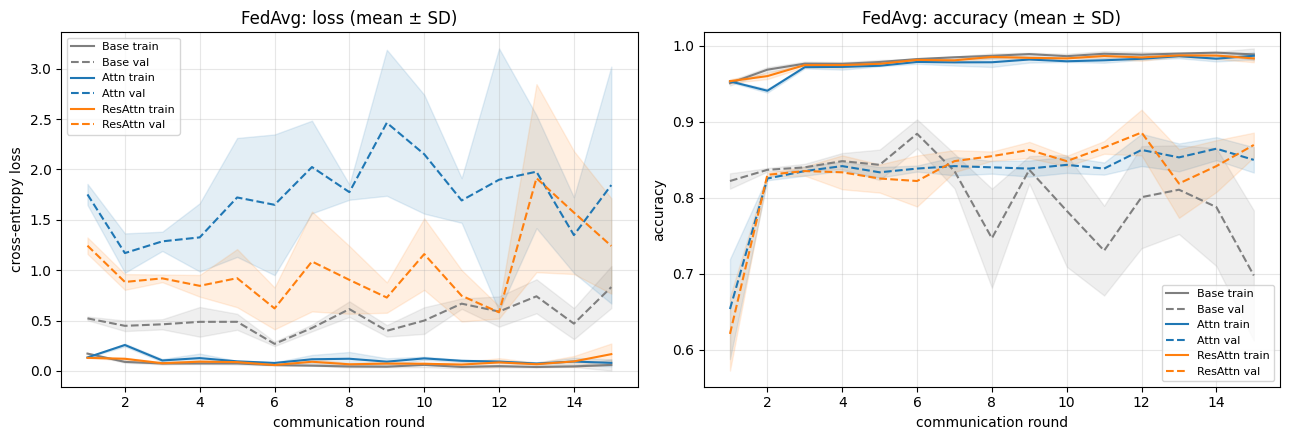

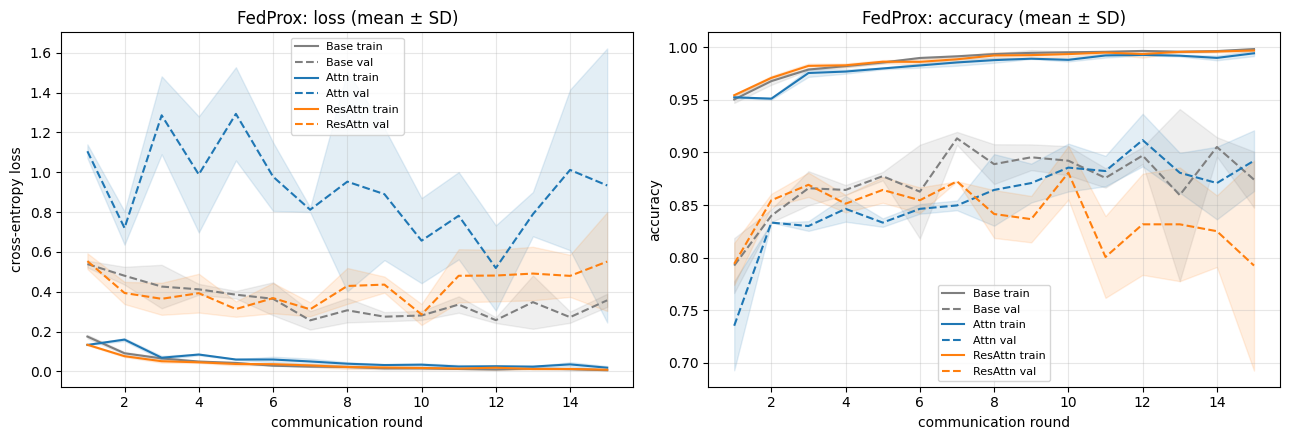

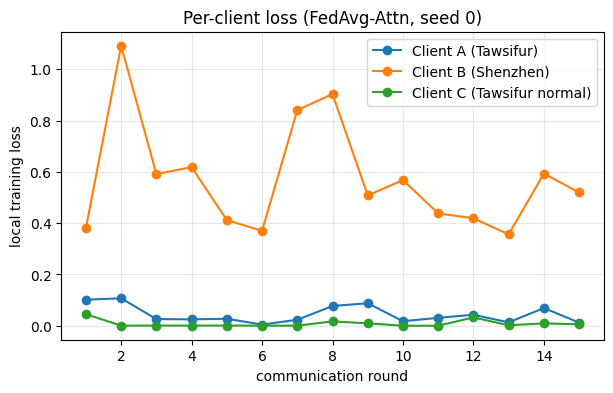

In [21]:
COLORS = {"Base": "tab:gray", "Attn": "tab:blue", "ResAttn": "tab:orange"}

def plot_convergence(method, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for arch, col in COLORS.items():
        H = [r["hist"] for r in runs("paper", f"{method}-{arch}")]
        if not H: continue
        rr = H[0]["round"].values
        for k, (lk, ak) in enumerate((("train_loss", "val_loss"), ("train_acc", "val_acc"))):
            for key, ls in ((lk, "-"), (ak, "--")):
                a = np.stack([h[key].values for h in H]); m, sd = a.mean(0), a.std(0)
                ax[k].plot(rr, m, ls, color=col, label=f"{arch} {key.split('_')[0]}")
                ax[k].fill_between(rr, m - sd, m + sd, color=col, alpha=.12)
    ax[0].set(xlabel="communication round", ylabel="cross-entropy loss", title=f"{method}: loss (mean ± SD)")
    ax[1].set(xlabel="communication round", ylabel="accuracy", title=f"{method}: accuracy (mean ± SD)")
    for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
    plt.tight_layout(); savefig(fname); plt.show()

plot_convergence("FedAvg", "convergence_fedavg.png")
if RUN_FEDPROX: plot_convergence("FedProx", "convergence_fedprox.png")

h = MAIN_RES["hist"]
plt.figure(figsize=(7, 4))
for name in CLIENT_SETS["paper"]: plt.plot(h["round"], h[f"{name} loss"], marker="o", label=name)
plt.xlabel("communication round"); plt.ylabel("local training loss"); plt.title(f"Per-client loss ({PROPOSED}, seed {MAIN_SEED})")
plt.grid(alpha=.3); plt.legend(); savefig("client_losses.png"); plt.show()

## Classification curves

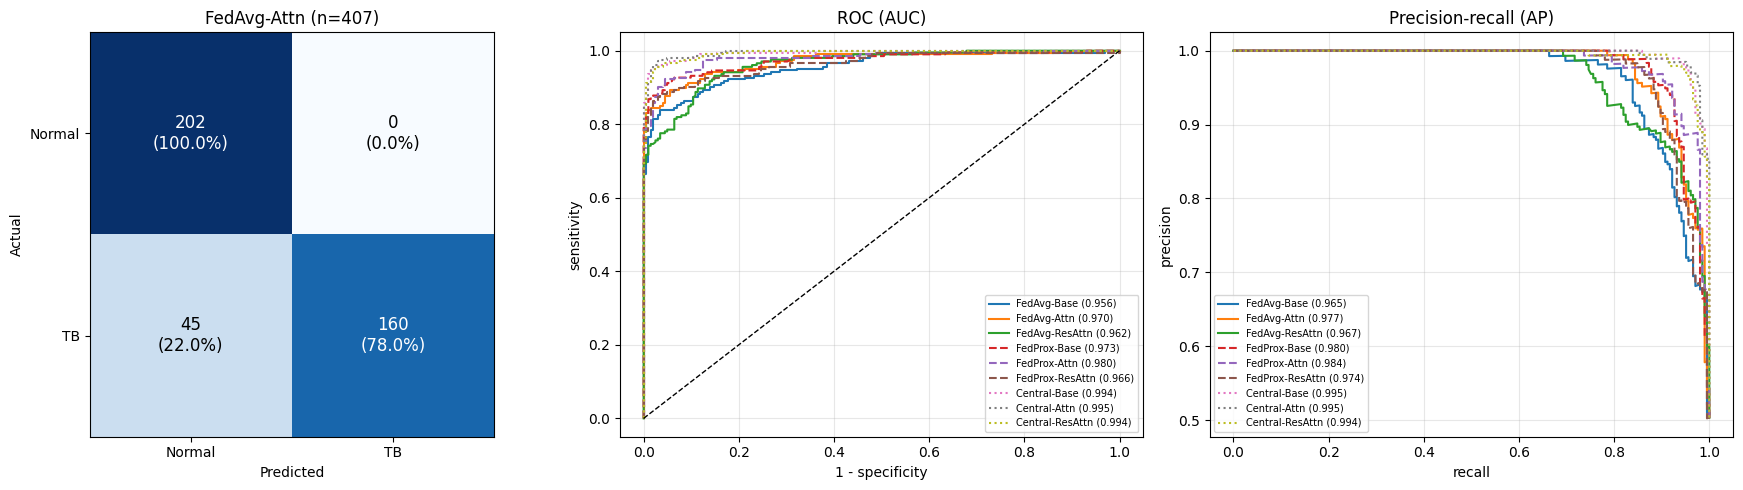

In [22]:
cm = skm.confusion_matrix(y_test, (p_main >= .5).astype(int), labels=[0, 1])
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "TB"], yticklabels=["Normal", "TB"],
          xlabel="Predicted", ylabel="Actual", title=f"{PROPOSED} (n={len(y_test)})")
for name in NAMES:
    p = RESULTS[("paper", name, MAIN_SEED)]["p_test"]
    fpr, tpr, _ = skm.roc_curve(y_test, p); pr, rc, _ = skm.precision_recall_curve(y_test, p)
    ls = "-" if name.startswith("FedAvg") else ("--" if name.startswith("FedProx") else ":")
    ax[1].plot(fpr, tpr, ls, label=f"{name} ({skm.roc_auc_score(y_test, p):.3f})")
    ax[2].plot(rc, pr, ls, label=f"{name} ({skm.average_precision_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlabel="1 - specificity", ylabel="sensitivity", title="ROC (AUC)")
ax[2].set(xlabel="recall", ylabel="precision", title="Precision-recall (AP)")
for a in ax[1:]: a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); savefig("confusion_roc_pr.png"); plt.show()

## Calibration and decision curve

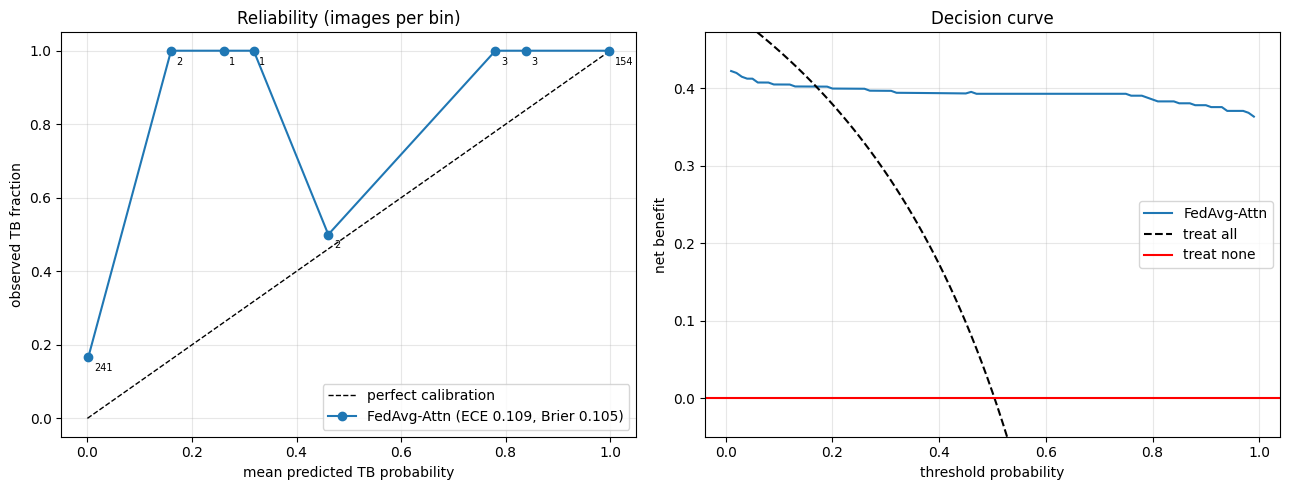

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
edges = np.linspace(0, 1, 11); ids = np.clip(np.digitize(p_main, edges[1:-1]), 0, 9)
bins = [b for b in range(10) if (ids == b).any()]
conf = [p_main[ids == b].mean() for b in bins]; acc = [y_test[ids == b].mean() for b in bins]; cnt = [(ids == b).sum() for b in bins]
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax[0].plot(conf, acc, "o-", label=f"{PROPOSED} (ECE {m_main['ece']:.3f}, Brier {m_main['brier']:.3f})")
for c_, a_, n_ in zip(conf, acc, cnt): ax[0].annotate(str(n_), (c_, a_), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax[0].set(xlabel="mean predicted TB probability", ylabel="observed TB fraction", title="Reliability (images per bin)")
ax[0].legend(); ax[0].grid(alpha=.3)

th = np.linspace(0.01, 0.99, 99); n = len(y_test); prev = y_test.mean()
nb_model = [((p_main >= t) & (y_test == 1)).sum() / n - ((p_main >= t) & (y_test == 0)).sum() / n * t / (1 - t) for t in th]
nb_all = [prev - (1 - prev) * t / (1 - t) for t in th]
ax[1].plot(th, nb_model, label=PROPOSED); ax[1].plot(th, nb_all, "k--", label="treat all"); ax[1].axhline(0, color="r", label="treat none")
ax[1].set(ylim=(-0.05, max(nb_model) + 0.05), xlabel="threshold probability", ylabel="net benefit", title="Decision curve")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); savefig("calibration_dca.png"); plt.show()

## Feature space and source probe

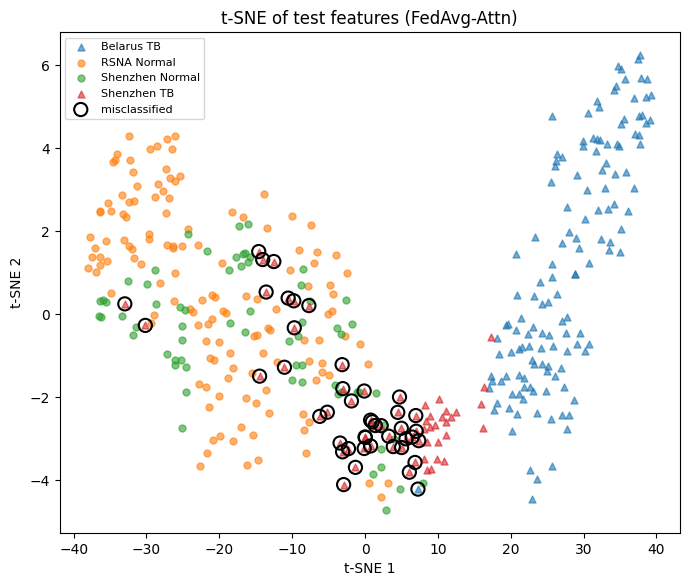

                          features    cls             origins   n  balanced_acc_mean  balanced_acc_sd
ImageNet DenseNet121 (no training) Normal    RSNA vs Shenzhen 202              0.973            0.023
ImageNet DenseNet121 (no training)     TB Belarus vs Shenzhen 205              1.000            0.000
                       FedAvg-Base Normal    RSNA vs Shenzhen 202              0.992            0.015
                       FedAvg-Base     TB Belarus vs Shenzhen 205              1.000            0.000
                       FedAvg-Attn Normal    RSNA vs Shenzhen 202              0.969            0.029
                       FedAvg-Attn     TB Belarus vs Shenzhen 205              0.982            0.017
                    FedAvg-ResAttn Normal    RSNA vs Shenzhen 202              0.973            0.023
                    FedAvg-ResAttn     TB Belarus vs Shenzhen 205              0.993            0.014
                      FedProx-Base Normal    RSNA vs Shenzhen 202              0.9

In [24]:
@torch.no_grad()
def embeddings(model, split):
    model.eval()
    return torch.cat([model.embed(model.forward_features(xb)).float().cpu() for xb, _ in batches(split, 64, False)]).numpy()

def load_model(part, name, seed=MAIN_SEED):
    r = RESULTS[(part, name, seed)]
    m = ARCH[r["arch"]]().to(device); m.load_state_dict(torch.load(r["weights"], map_location=device)); return m.eval()

E_main = embeddings(MAIN_MODEL, TEST)
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(E_main)
wrong = (p_main >= .5).astype(int) != y_test
plt.figure(figsize=(8, 6.5))
for org in np.unique(TEST.origin):
    for lab, mk in ((0, "o"), (1, "^")):
        m = (TEST.origin == org) & (y_test == lab)
        if m.any(): plt.scatter(Z[m, 0], Z[m, 1], marker=mk, s=25, alpha=.6, label=f"{org} {'TB' if lab else 'Normal'}")
plt.scatter(Z[wrong, 0], Z[wrong, 1], facecolors="none", edgecolors="k", s=90, lw=1.5, label="misclassified")
plt.legend(fontsize=8); plt.title(f"t-SNE of test features ({PROPOSED})"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
savefig("tsne_origin.png"); plt.show()

def probe(E, name):
    rows = []
    for lab in (0, 1):
        m = y_test == lab; org = TEST.origin[m]
        u, c = np.unique(org, return_counts=True)
        if len(u) < 2 or c.min() < 10: continue
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1))
        sc = cross_val_score(clf, E[m], org, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="balanced_accuracy")
        rows.append(dict(features=name, cls="TB" if lab else "Normal", origins=" vs ".join(u), n=int(m.sum()),
                         balanced_acc_mean=sc.mean(), balanced_acc_sd=sc.std()))
    return rows

probe_rows = probe(embeddings(DenseNetBaseline().to(device), TEST), "ImageNet DenseNet121 (no training)")
for name in NAMES:
    model = load_model("paper", name)
    probe_rows += probe(embeddings(model, TEST), name); del model
TABLE_PROBE = pd.DataFrame(probe_rows)
print(TABLE_PROBE.round(3).to_string(index=False))
save_table(TABLE_PROBE, "table_source_probe.csv")

## Explainability

{
  "n_tb_images": 205,
  "border_energy_mean": 0.2784970998764038,
  "border_energy_uniform": 0.35427295918367346,
  "upper_half_energy_mean": 0.3066590428352356,
  "upper_half_uniform": 0.5,
  "border_energy_by_origin": {
    "Belarus": 0.2830178737640381,
    "Shenzhen": 0.2693890929222107
  }
}


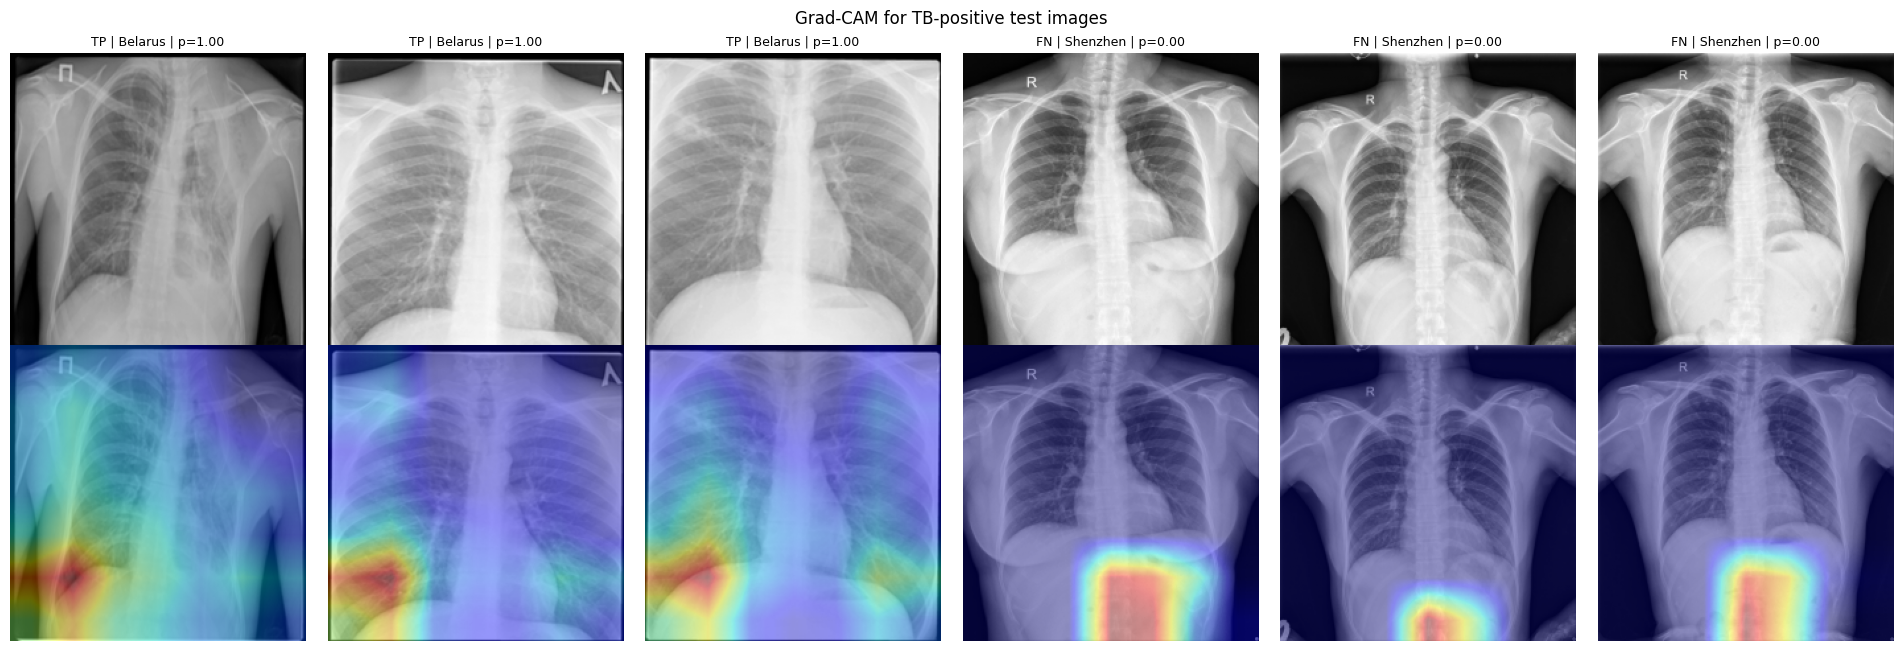

In [25]:
def gradcam(model, x, target=1):
    model.eval()
    with torch.enable_grad():
        feats = model.forward_features(x); feats.retain_grad()
        logits = model.forward_head(feats)
        model.zero_grad(set_to_none=True); logits[:, target].sum().backward()
        cam = F.relu((feats.grad.mean(dim=(2, 3), keepdim=True) * feats).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin((1, 2), keepdim=True); cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy()

tb_pos = np.where(y_test == 1)[0]
CAMS = np.concatenate([gradcam(MAIN_MODEL, to_input(TEST.X[tb_pos[i:i + 16]])) for i in range(0, len(tb_pos), 16)])
fr = int(0.10 * IMG); frame = np.ones((IMG, IMG), bool); frame[fr:-fr, fr:-fr] = False
border = (CAMS * frame).sum((1, 2)) / (CAMS.sum((1, 2)) + 1e-8)
upper = CAMS[:, :IMG // 2].sum((1, 2)) / (CAMS.sum((1, 2)) + 1e-8)
GRADCAM_STATS = dict(n_tb_images=int(len(tb_pos)), border_energy_mean=float(border.mean()),
                     border_energy_uniform=float(frame.mean()), upper_half_energy_mean=float(upper.mean()),
                     upper_half_uniform=0.5,
                     border_energy_by_origin={o: float(border[TEST.origin[tb_pos] == o].mean())
                                              for o in np.unique(TEST.origin[tb_pos])})
print(json.dumps(GRADCAM_STATS, indent=2))

pred = (p_main >= .5).astype(int)
tp_idx = [i for i in np.argsort(-p_main) if y_test[i] == 1 and pred[i] == 1][:3]
fn_idx = [i for i in np.argsort(p_main) if y_test[i] == 1 and pred[i] == 0][:3]
show = [(i, "TP") for i in tp_idx] + [(i, "FN") for i in fn_idx]
pos_of = {v: k for k, v in enumerate(tb_pos)}
if show:
    fig, ax = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6)); ax = np.array(ax).reshape(2, -1)
    for k, (i, kind) in enumerate(show):
        img = TEST.X[i].numpy()
        ax[0, k].imshow(img, cmap="gray"); ax[0, k].set_title(f"{kind} | {TEST.origin[i]} | p={p_main[i]:.2f}", fontsize=9)
        ax[1, k].imshow(img, cmap="gray"); ax[1, k].imshow(CAMS[pos_of[i]], cmap="jet", alpha=.4)
        for a in ax[:, k]: a.axis("off")
    plt.suptitle("Grad-CAM for TB-positive test images"); plt.tight_layout(); savefig("gradcam.png"); plt.show()

{
  "n_images": 50,
  "noise_sigma": 0.05,
  "spearman_mean": 0.4420742171633535,
  "spearman_sd": 0.1203965942633454,
  "top10_iou_mean": 0.19459576612572416,
  "top10_iou_sd": 0.06069779526707264
}


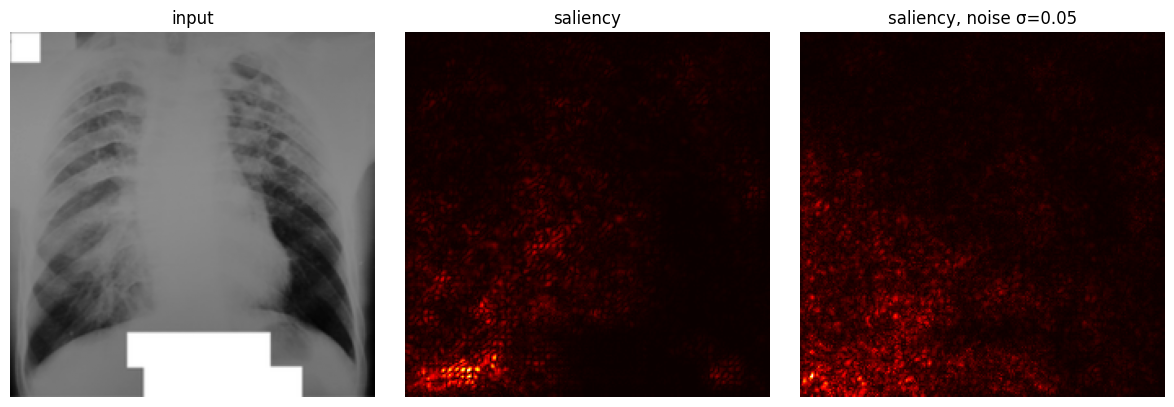

In [26]:
def saliency(model, x, target):
    model.eval()
    with torch.enable_grad():
        x = x.clone().requires_grad_(True)
        out = model(x); out[torch.arange(len(x), device=x.device), target].sum().backward()
    return x.grad.abs().amax(1).detach().cpu().numpy()

NOISE_SIGMA = 0.05
g = torch.Generator().manual_seed(0)
sel = torch.randperm(len(TEST), generator=g)[:50].numpy()
rho, iou = [], []
for i in range(0, len(sel), 10):
    j = sel[i:i + 10]; x = to_input(TEST.X[j]); tgt = torch.tensor(pred[j], device=device)
    s0 = saliency(MAIN_MODEL, x, tgt)
    s1 = saliency(MAIN_MODEL, x + NOISE_SIGMA * torch.randn(x.shape, generator=g).to(device), tgt)
    for a, b in zip(s0, s1):
        rho.append(stats.spearmanr(a.ravel(), b.ravel())[0])
        ta, tb_ = a >= np.quantile(a, .9), b >= np.quantile(b, .9)
        iou.append((ta & tb_).sum() / (ta | tb_).sum())
SALIENCY_STATS = dict(n_images=len(rho), noise_sigma=NOISE_SIGMA, spearman_mean=float(np.mean(rho)),
                      spearman_sd=float(np.std(rho)), top10_iou_mean=float(np.mean(iou)), top10_iou_sd=float(np.std(iou)))
print(json.dumps(SALIENCY_STATS, indent=2))

x = to_input(TEST.X[sel[:1]]); tgt = torch.tensor(pred[sel[:1]], device=device)
a = saliency(MAIN_MODEL, x, tgt)[0]; b = saliency(MAIN_MODEL, x + NOISE_SIGMA * torch.randn_like(x), tgt)[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(TEST.X[sel[0]].numpy(), cmap="gray"); ax[0].set_title("input")
ax[1].imshow(a, cmap="hot"); ax[1].set_title("saliency"); ax[2].imshow(b, cmap="hot"); ax[2].set_title(f"saliency, noise σ={NOISE_SIGMA}")
for a_ in ax: a_.axis("off")
plt.tight_layout(); savefig("saliency_stability.png"); plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

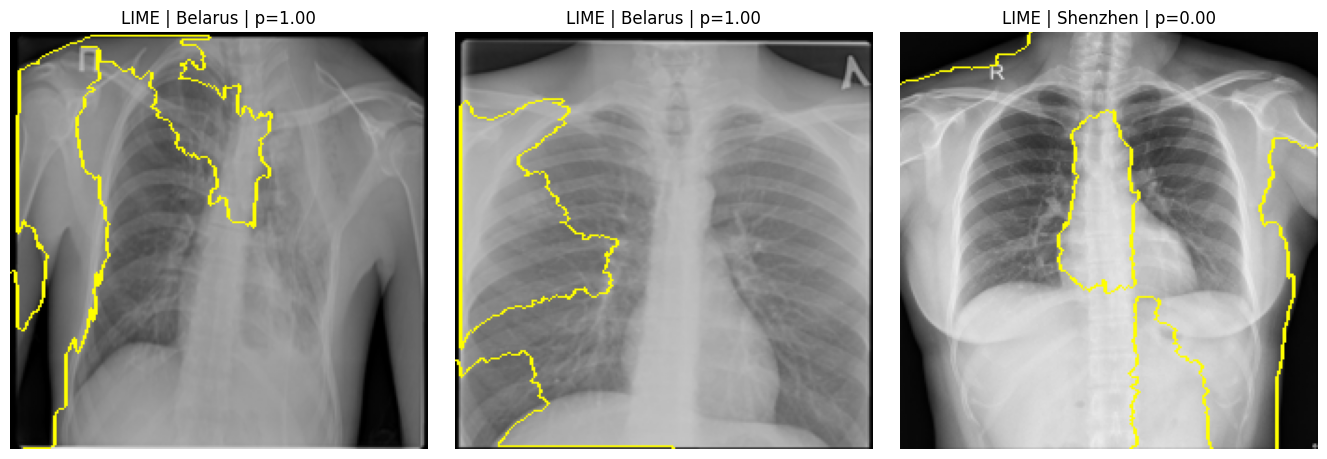

In [27]:
try:
    from lime import lime_image
    from skimage.segmentation import mark_boundaries

    @torch.no_grad()
    def lime_predict(batch):
        x = torch.tensor(batch, dtype=torch.float32, device=device).permute(0, 3, 1, 2)
        return torch.softmax(MAIN_MODEL((x - MEAN) / STD).float(), 1).cpu().numpy()

    explainer = lime_image.LimeImageExplainer(random_state=0)
    idxs = tp_idx[:2] + fn_idx[:1]
    fig, ax = plt.subplots(1, len(idxs), figsize=(4.5 * len(idxs), 4.5)); ax = np.atleast_1d(ax)
    for k, i in enumerate(idxs):
        rgb = np.repeat(TEST.X[i].numpy()[..., None], 3, 2).astype(np.float64) / 255
        exp = explainer.explain_instance(rgb, lime_predict, labels=(1,), top_labels=None, hide_color=0,
                                         num_samples=1000, batch_size=32, random_seed=0)
        temp, mask = exp.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
        ax[k].imshow(mark_boundaries(temp, mask)); ax[k].set_title(f"LIME | {TEST.origin[i]} | p={p_main[i]:.2f}"); ax[k].axis("off")
    plt.tight_layout(); savefig("lime.png"); plt.show()
except ImportError:
    print("lime is not installed; pip install lime to run this cell")

## False negatives

false negatives: 45 of 205 TB test images
Shenzhen    44
Belarus      1


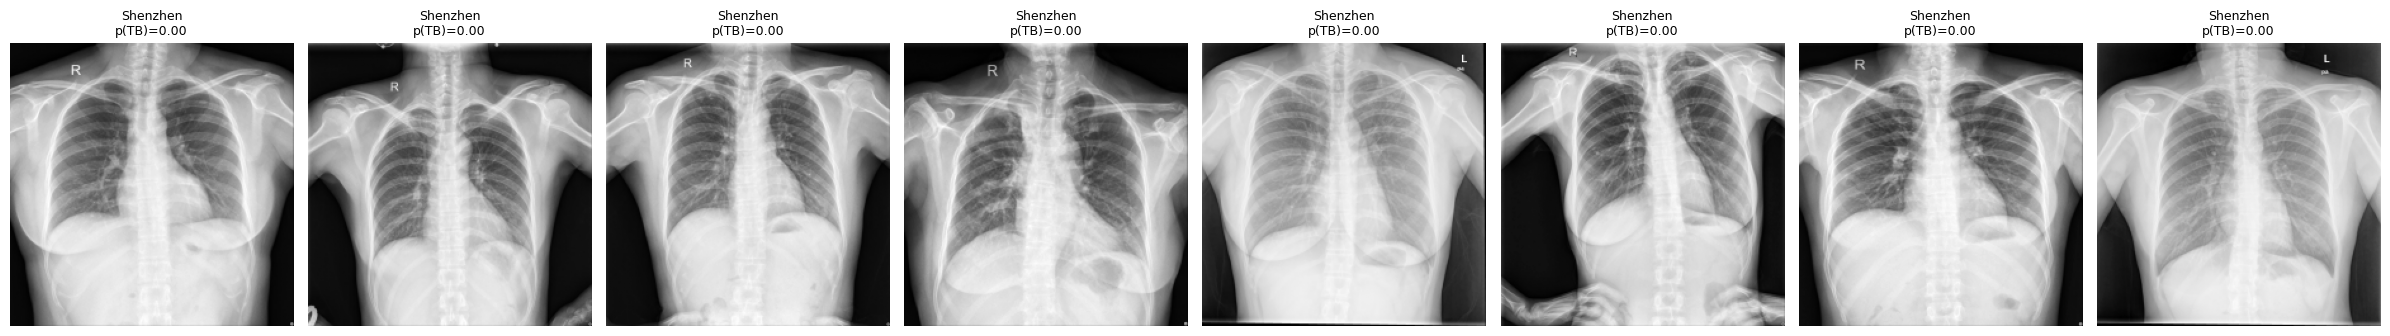

In [28]:
fn_all = [i for i in np.argsort(p_main) if y_test[i] == 1 and pred[i] == 0]
print(f"false negatives: {len(fn_all)} of {int((y_test == 1).sum())} TB test images")
if fn_all:
    print(pd.Series(TEST.origin[fn_all]).value_counts().to_string())
    k = min(8, len(fn_all)); fig, ax = plt.subplots(1, k, figsize=(3 * k, 3.4)); ax = np.atleast_1d(ax)
    for a, i in zip(ax, fn_all[:k]):
        a.imshow(TEST.X[i].numpy(), cmap="gray"); a.set_title(f"{TEST.origin[i]}\np(TB)={p_main[i]:.2f}", fontsize=9); a.axis("off")
    plt.tight_layout(); savefig("false_negatives.png"); plt.show()
save_table(pd.DataFrame(dict(path=TEST.path[fn_all], origin=TEST.origin[fn_all], p_tb=p_main[fn_all])), "false_negatives.csv")

## Inference cost

In [29]:
def benchmark(model, dev, bs=1, iters=200, warmup=20):
    model = copy.deepcopy(model).to(dev).eval(); x = torch.randn(bs, 3, IMG, IMG, device=dev); t = []
    with torch.no_grad():
        for _ in range(warmup): model(x)
        if dev.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        for _ in range(iters):
            if dev.type == "cuda": torch.cuda.synchronize()
            s = time.perf_counter(); model(x)
            if dev.type == "cuda": torch.cuda.synchronize()
            t.append((time.perf_counter() - s) * 1000)
    peak = torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else np.nan
    return float(np.mean(t)), float(np.std(t)), peak

eff = []
for arch, cls in ARCH.items():
    m = cls(); m.load_state_dict(torch.load(RESULTS[("paper", f"FedAvg-{arch}", MAIN_SEED)]["weights"], map_location="cpu"))
    size_mb = sum(t.numel() * t.element_size() for t in list(m.parameters()) + list(m.buffers())) / 2**20
    row = dict(model=arch, params=n_params(m), size_MB_fp32=round(size_mb, 2))
    if device.type == "cuda":
        mu_, sd_, peak = benchmark(m, device); mu32, _, _ = benchmark(m, device, bs=32, iters=50)
        row.update(gpu=ENV["gpu"], gpu_ms_bs1=round(mu_, 2), gpu_ms_bs1_sd=round(sd_, 2), gpu_fps_bs1=round(1000 / mu_, 1),
                   gpu_imgs_per_s_bs32=round(32_000 / mu32, 1), gpu_peak_MB_bs1=round(peak, 1))
    mu_, _, _ = benchmark(m, torch.device("cpu"), iters=20, warmup=3)
    row.update(cpu_ms_bs1=round(mu_, 1), cpu_threads=torch.get_num_threads())
    eff.append(row)
TABLE_EFF = pd.DataFrame(eff); print(TABLE_EFF.T.to_string())
save_table(TABLE_EFF, "table_efficiency.csv")

                            0         1         2
model                    Base      Attn   ResAttn
params                7216770  11415170  13568642
size_MB_fp32            27.85     43.87     52.08
gpu                  Tesla T4  Tesla T4  Tesla T4
gpu_ms_bs1              16.06     16.26     18.16
gpu_ms_bs1_sd            0.57       0.5      1.76
gpu_fps_bs1              62.3      61.5      55.1
gpu_imgs_per_s_bs32     300.4     285.1     272.7
gpu_peak_MB_bs1         144.1     160.1     168.3
cpu_ms_bs1               84.8      93.8      94.8
cpu_threads                 2         2         2


## Export

In [30]:
def records(t): return t.to_dict("records") if isinstance(t, pd.DataFrame) else t

PAPER = dict(
    environment=ENV,
    config=dict(IMG=IMG, BLUR_THRESHOLD=BLUR_THRESHOLD, NEAR_DUP_CORR=NEAR_DUP_CORR, CROSS_DUP_CORR=CROSS_DUP_CORR,
                CROSS_CROP_SCALES=list(CROSS_CROP_SCALES), SPLIT=SPLIT, DATA_SEED=DATA_SEED, SEEDS=SEEDS,
                CLIENT_C_SIZE=CLIENT_C_SIZE, PARTITIONS=list(PARTITION_IDX), NUM_ROUNDS=NUM_ROUNDS,
                LOCAL_EPOCHS=LOCAL_EPOCHS, BATCH_SIZE=BATCH_SIZE, LR=LR, WEIGHTED_FEDAVG=WEIGHTED_FEDAVG,
                FEDPROX_MUS=FEDPROX_MUS, FEDPROX_MU_SELECTED=MU_CHOICE, USE_AMP=USE_AMP, SPLIT_ID=SPLIT_ID,
                model_selection="lowest validation loss", threshold_selection="Youden J on validation"),
    cleaning=CLEANING.reset_index().to_dict("records"), cross_collection_audit=AUDIT, origins=records(ORIGINS),
    near_duplicates=NEAR_DUP, data_distribution=records(TABLE_DATA), parameters=N_PARAMS,
    main_results=records(TABLE_MAIN), main_model_ci=records(TABLE_MAIN_CI), per_group=records(TABLE_GROUPS),
    partition_controls=records(TABLE_CONTROLS), fedprox_mu_search=MU_SEARCH, stats=records(TABLE_STATS),
    source_probe=records(TABLE_PROBE), gradcam=GRADCAM_STATS, saliency=SALIENCY_STATS, efficiency=records(TABLE_EFF),
    per_run={f"{p} | {n} | seed {s}": dict(best_round=r["best_round"], thr_val=r["thr_val"], mu=r["mu"],
                                           **{k: r["metrics"][k] for k in KEYS})
             for (p, n, s), r in RESULTS.items()},
)
json.dump(PAPER, open(os.path.join(OUT_DIR, "paper_numbers.json"), "w"), indent=2, default=float)
zip_path = shutil.make_archive(OUT_DIR, "zip", root_dir=OUT_DIR)
print("saved", os.path.join(OUT_DIR, "paper_numbers.json"))
print(f"archive {zip_path} ({os.path.getsize(zip_path) / 2**20:.1f} MB)")
print("figures:", sorted(os.listdir(FIG_DIR)))

saved /kaggle/working/tb_fl_outputs/paper_numbers.json
archive /kaggle/working/tb_fl_outputs.zip (1968.1 MB)
figures: ['blur_by_origin.png', 'calibration_dca.png', 'client_losses.png', 'confusion_roc_pr.png', 'convergence_fedavg.png', 'convergence_fedprox.png', 'cross_collection_hist.png', 'cross_collection_pairs.png', 'false_negatives.png', 'gradcam.png', 'lime.png', 'saliency_stability.png', 'tsne_origin.png']


In [31]:
import os, zipfile
from IPython.display import FileLink, display

os.chdir("/kaggle/working")
src = "tb_fl_outputs"

with zipfile.ZipFile("tb_fl_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(src):
        for f in files:
            if not f.endswith(".pt"):
                z.write(os.path.join(root, f))

with zipfile.ZipFile("tb_fl_full.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(src):
        for f in files:
            z.write(os.path.join(root, f))

for f in ("tb_fl_results.zip", "tb_fl_full.zip"):
    print(f, f"{os.path.getsize(f) / 2**20:.1f} MB")
    display(FileLink(f))

tb_fl_results.zip 6.9 MB


/kaggle/working/tb_fl_results.zip

tb_fl_full.zip 1968.2 MB


/kaggle/working/tb_fl_full.zip

    source          origin  label  images
Montgomery      Montgomery      0      80
Montgomery      Montgomery      1      58
  Shenzhen        Shenzhen      0     326
  Shenzhen        Shenzhen      1     336
  Tawsifur Tawsifur Normal      0    3500
  Tawsifur     Tawsifur TB      1     697


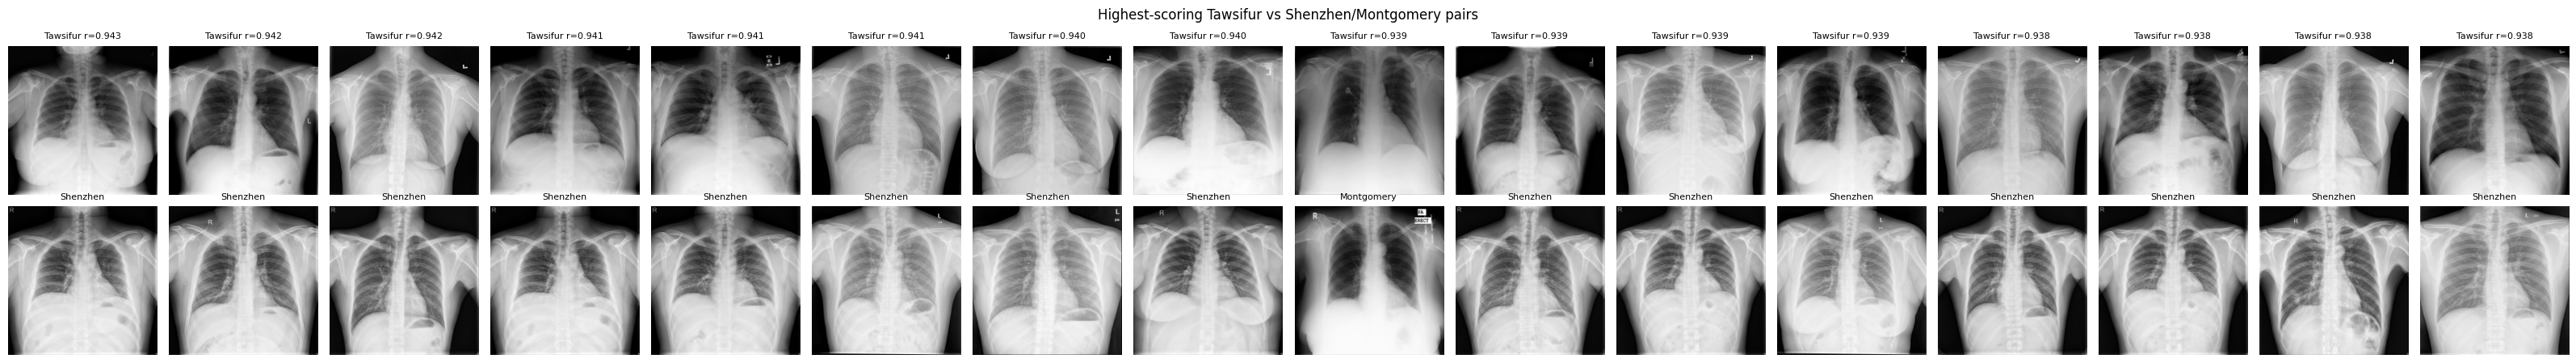

max cross-collection score: 0.9435

=== label_balanced | FedAvg-Base | seed 0 ===
  round  1 | train 0.1925/0.9377 | val 0.6801/0.8284 auc 0.8818 | 28s
  round  2 | train 0.0964/0.9647 | val 1.0145/0.8333 auc 0.9347 | 27s
  round  3 | train 0.1011/0.9701 | val 1.5043/0.8333 auc 0.8868 | 26s
  round  4 | train 0.1257/0.9709 | val 1.4371/0.8333 auc 0.9263 | 27s
  round  5 | train 0.1054/0.9754 | val 1.5305/0.8333 auc 0.9728 | 26s
  round  6 | train 0.0800/0.9799 | val 1.8619/0.8333 auc 0.9700 | 26s
  round  7 | train 0.0786/0.9832 | val 2.6758/0.8333 auc 0.9373 | 26s
  round  8 | train 0.0851/0.9840 | val 2.5236/0.8333 auc 0.9641 | 26s
  round  9 | train 0.0826/0.9848 | val 2.2603/0.8333 auc 0.9356 | 26s
  round 10 | train 0.0680/0.9850 | val 2.9055/0.8333 auc 0.9078 | 26s
  round 11 | train 0.0374/0.9910 | val 2.7228/0.8333 auc 0.9519 | 26s
  round 12 | train 0.0549/0.9887 | val 2.6038/0.8333 auc 0.9381 | 26s
  round 13 | train 0.0408/0.9922 | val 2.1321/0.8333 auc 0.9820 | 26s
  round 

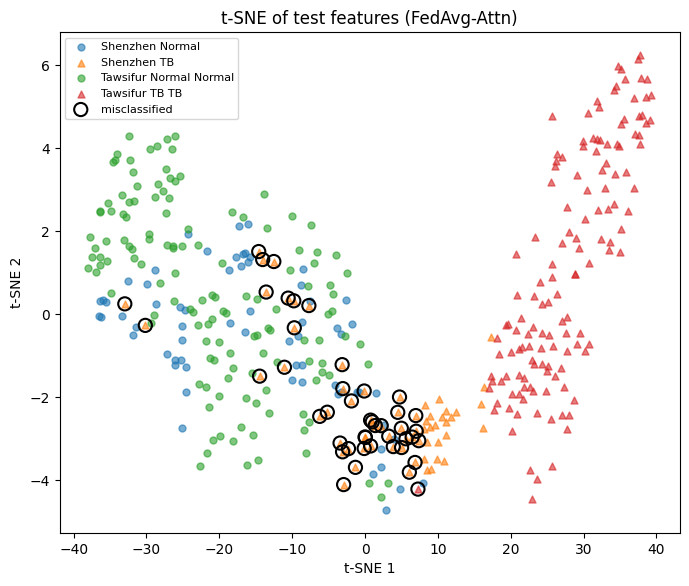

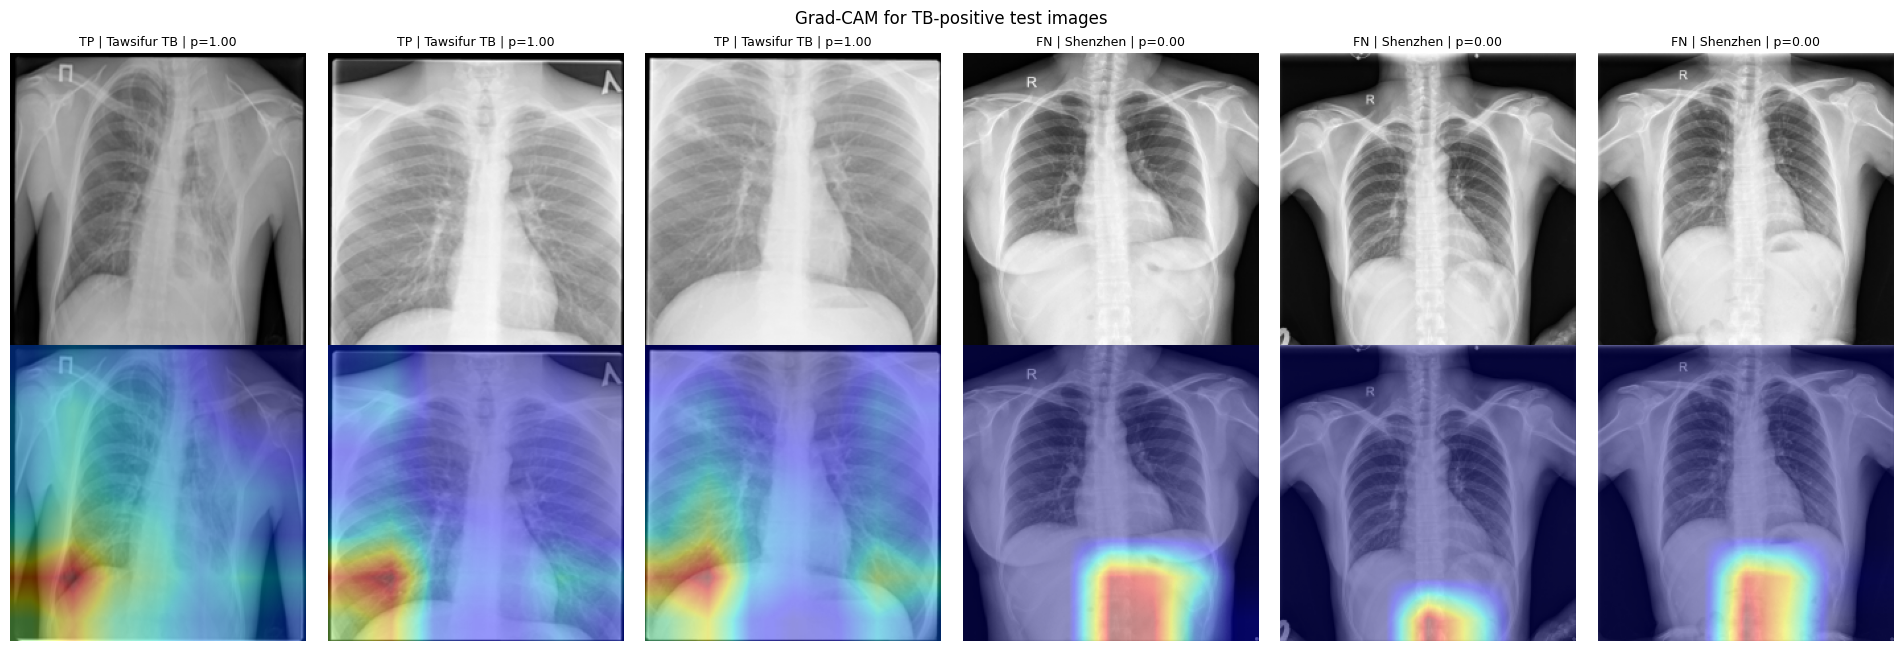

Shenzhen       44
Tawsifur TB     1


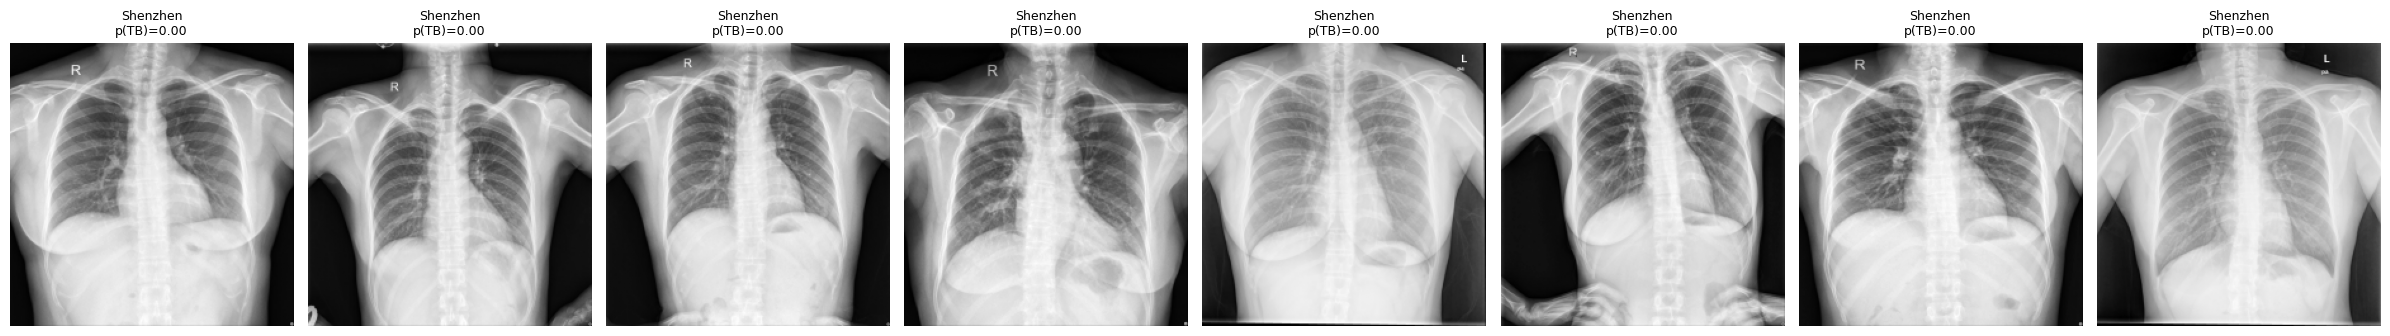

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

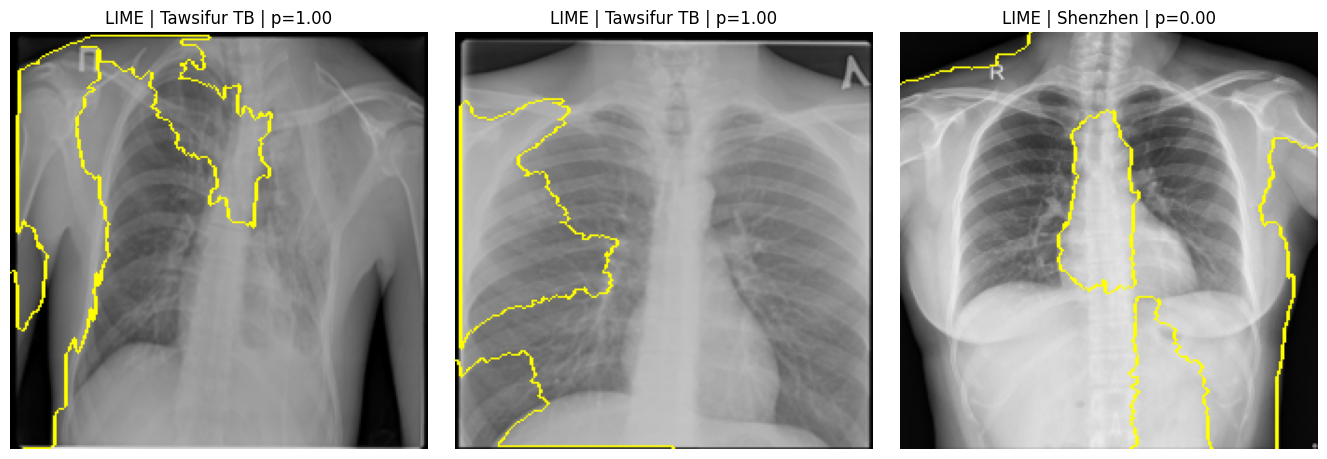

/kaggle/working/tb_fl_results_v2.zip (10.9 MB)


/kaggle/working/tb_fl_results_v2.zip

In [32]:
RENAME = {"Belarus": "Tawsifur TB", "RSNA": "Tawsifur Normal"}
df["origin"] = df["origin"].replace(RENAME)
for s in [VAL, TEST, EXT] + [x for c in CLIENT_SETS.values() for x in c.values()] + list(POOLED_SETS.values()):
    s.origin = df.loc[s.idx, "origin"].values
ORIGINS = df.groupby(["source", "origin", "label"]).size().rename("images").reset_index()
save_table(ORIGINS, "origins.csv")
print(ORIGINS.to_string(index=False))

if AUDIT["n_copies"] == 0:
    top = np.argsort(-cross_best)[:16]
    fig, ax = plt.subplots(2, len(top), figsize=(2 * len(top), 4.6))
    for c, t in enumerate(top):
        ax[0, c].imshow(IMGS[tw[t]], cmap="gray"); ax[0, c].set_title(f"Tawsifur r={cross_best[t]:.3f}", fontsize=8)
        ax[1, c].imshow(IMGS[cross_match[t]], cmap="gray"); ax[1, c].set_title(df.source[cross_match[t]], fontsize=8)
    for a in ax.ravel(): a.axis("off")
    plt.suptitle("Highest-scoring Tawsifur vs Shenzhen/Montgomery pairs"); plt.tight_layout()
    savefig("cross_collection_top_pairs.png"); plt.show()
    AUDIT["max_score"] = float(cross_best.max())
    print("max cross-collection score:", round(AUDIT["max_score"], 4))

n_tb, n_nm = len(tw_tb), len(tw_tb) + CLIENT_C_SIZE
PARTITION_IDX["label_balanced"] = {
    "Client A (Tawsifur)": np.concatenate([tw_tb[:n_tb // 2], tw_nm[:n_nm // 2]]),
    "Client B (Shenzhen)": paper_clients["Client B (Shenzhen)"],
    "Client C (Tawsifur)": np.concatenate([tw_tb[n_tb // 2:], tw_nm[n_nm // 2:n_nm]]),
}
assert sorted(np.concatenate(list(PARTITION_IDX["label_balanced"].values()))) == sorted(used_train)
CLIENT_SETS["label_balanced"] = {n: Split(i) for n, i in PARTITION_IDX["label_balanced"].items()}
POOLED_SETS["label_balanced"] = Split(np.concatenate(list(PARTITION_IDX["label_balanced"].values())))
for seed in SEEDS:
    for arch in ARCH:
        RESULTS[("label_balanced", f"FedAvg-{arch}", seed)] = execute("label_balanced", f"FedAvg-{arch}", arch, seed, "fedavg")

rows = []
for part, clients in PARTITION_IDX.items():
    n_all = sum(len(v) for v in clients.values())
    for name, idx in clients.items():
        rows.append(describe(name, idx, part) | dict(fedavg_weight=round(len(idx) / n_all, 3)))
for name, idx in (("Validation", val_idx), ("Test", test_idx), ("External (Montgomery)", ext_idx)):
    rows.append(describe(name, idx, "all"))
TABLE_DATA = pd.DataFrame(rows)
print(TABLE_DATA.to_string(index=False)); save_table(TABLE_DATA, "table_data_distribution.csv")

pred_df = pd.DataFrame(dict(path=TEST.path, source=TEST.source, origin=TEST.origin, label=y_test))
ext_df = pd.DataFrame(dict(path=EXT.path, label=y_ext))
for (part, name, seed), r in RESULTS.items():
    pred_df[f"{part} | {name} | seed {seed}"] = r["p_test"]; ext_df[f"{part} | {name} | seed {seed}"] = r["p_ext"]
save_table(pred_df, "test_predictions_all_runs.csv"); save_table(ext_df, "external_predictions_all_runs.csv")

GROUPS = [("Test: all", "test", np.ones(len(TEST), bool))]
GROUPS += [(f"Test source: {s}", "test", TEST.source == s) for s in np.unique(TEST.source)]
GROUPS += [(f"Test origin: {o}", "test", TEST.origin == o) for o in np.unique(TEST.origin) if o not in np.unique(TEST.source)]
GROUPS += [("External: Montgomery", "ext", np.ones(len(EXT), bool))]
TABLE_GROUPS = group_table("paper", NAMES)
save_table(TABLE_GROUPS, "table_per_source_origin.csv")

LABELS["label_balanced"] = "same images, sources kept, every client mixed-label"
rows = [summary_row(p, f"FedAvg-{a}", LABELS[p]) for p in PARTITION_IDX for a in ARCH]
rows += [summary_row("paper", f"FedProx-{a}", "FedProx, paper partition") for a in ARCH]
rows += [summary_row("paper", f"Central-{a}", "centralised, pooled data") for a in ARCH]
TABLE_CONTROLS = pd.DataFrame([r for r in rows if r])
print(TABLE_CONTROLS.to_string(index=False)); save_table(TABLE_CONTROLS, "table_partition_controls.csv")

if "origins" in TABLE_PROBE:
    for old, new in RENAME.items():
        TABLE_PROBE["origins"] = TABLE_PROBE["origins"].str.replace(old, new, regex=False)
save_table(TABLE_PROBE, "table_source_probe.csv")
GRADCAM_STATS["border_energy_by_origin"] = {RENAME.get(k, k): v for k, v in GRADCAM_STATS["border_energy_by_origin"].items()}

plt.figure(figsize=(8, 6.5))
for org in np.unique(TEST.origin):
    for lab, mk in ((0, "o"), (1, "^")):
        m = (TEST.origin == org) & (y_test == lab)
        if m.any(): plt.scatter(Z[m, 0], Z[m, 1], marker=mk, s=25, alpha=.6, label=f"{org} {'TB' if lab else 'Normal'}")
plt.scatter(Z[wrong, 0], Z[wrong, 1], facecolors="none", edgecolors="k", s=90, lw=1.5, label="misclassified")
plt.legend(fontsize=8); plt.title(f"t-SNE of test features ({PROPOSED})"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
savefig("tsne_origin.png"); plt.show()

if show:
    fig, ax = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6)); ax = np.array(ax).reshape(2, -1)
    for k, (i, kind) in enumerate(show):
        img = TEST.X[i].numpy()
        ax[0, k].imshow(img, cmap="gray"); ax[0, k].set_title(f"{kind} | {TEST.origin[i]} | p={p_main[i]:.2f}", fontsize=9)
        ax[1, k].imshow(img, cmap="gray"); ax[1, k].imshow(CAMS[pos_of[i]], cmap="jet", alpha=.4)
        for a in ax[:, k]: a.axis("off")
    plt.suptitle("Grad-CAM for TB-positive test images"); plt.tight_layout(); savefig("gradcam.png"); plt.show()

if fn_all:
    print(pd.Series(TEST.origin[fn_all]).value_counts().to_string())
    k = min(8, len(fn_all)); fig, ax = plt.subplots(1, k, figsize=(3 * k, 3.4)); ax = np.atleast_1d(ax)
    for a, i in zip(ax, fn_all[:k]):
        a.imshow(TEST.X[i].numpy(), cmap="gray"); a.set_title(f"{TEST.origin[i]}\np(TB)={p_main[i]:.2f}", fontsize=9); a.axis("off")
    plt.tight_layout(); savefig("false_negatives.png"); plt.show()
save_table(pd.DataFrame(dict(path=TEST.path[fn_all], origin=TEST.origin[fn_all], p_tb=p_main[fn_all])), "false_negatives.csv")

try:
    from lime import lime_image
    from skimage.segmentation import mark_boundaries
    explainer = lime_image.LimeImageExplainer(random_state=0)
    idxs = tp_idx[:2] + fn_idx[:1]
    fig, ax = plt.subplots(1, len(idxs), figsize=(4.5 * len(idxs), 4.5)); ax = np.atleast_1d(ax)
    for k, i in enumerate(idxs):
        rgb = np.repeat(TEST.X[i].numpy()[..., None], 3, 2).astype(np.float64) / 255
        exp = explainer.explain_instance(rgb, lime_predict, labels=(1,), top_labels=None, hide_color=0,
                                         num_samples=1000, batch_size=32, random_seed=0)
        temp, mask = exp.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
        ax[k].imshow(mark_boundaries(temp, mask)); ax[k].set_title(f"LIME | {TEST.origin[i]} | p={p_main[i]:.2f}"); ax[k].axis("off")
    plt.tight_layout(); savefig("lime.png"); plt.show()
except ImportError:
    pass

PAPER["config"]["PARTITIONS"] = list(PARTITION_IDX)
PAPER.update(cross_collection_audit=AUDIT, origins=records(ORIGINS), data_distribution=records(TABLE_DATA),
             per_group=records(TABLE_GROUPS), partition_controls=records(TABLE_CONTROLS),
             source_probe=records(TABLE_PROBE), gradcam=GRADCAM_STATS,
             per_run={f"{p} | {n} | seed {s}": dict(best_round=r["best_round"], thr_val=r["thr_val"], mu=r["mu"],
                                                    **{k: r["metrics"][k] for k in KEYS})
                      for (p, n, s), r in RESULTS.items()})
json.dump(PAPER, open(os.path.join(OUT_DIR, "paper_numbers.json"), "w"), indent=2, default=float)

import zipfile
from IPython.display import FileLink, display
res_zip = os.path.join(os.path.dirname(OUT_DIR), "tb_fl_results_v2.zip")
with zipfile.ZipFile(res_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT_DIR):
        for f in files:
            if not f.endswith(".pt"):
                p = os.path.join(root, f); z.write(p, os.path.relpath(p, os.path.dirname(OUT_DIR)))
print(f"{res_zip} ({os.path.getsize(res_zip) / 2**20:.1f} MB)")
os.chdir(os.path.dirname(OUT_DIR)); display(FileLink(os.path.basename(res_zip)))

In [ ]:
import os, shutil
from IPython.display import FileLink, display
os.chdir("/kaggle/working")
shutil.copy("tb_fl_results_v2.zip", "IEEE_ICCIT_TuberFed_Federated_TB_Screening_Results.zip")
display(FileLink("IEEE_ICCIT_TuberFed_Federated_TB_Screening_Results.zip"))

/kaggle/working/ICCIT_TuberFed_Federated_TB_Screening_Results.zip